<a href="https://colab.research.google.com/github/sredward11/projeto_machine_learning/blob/feat%2Fmarco2-entrega/03_classificacao_prf2025_entrega.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

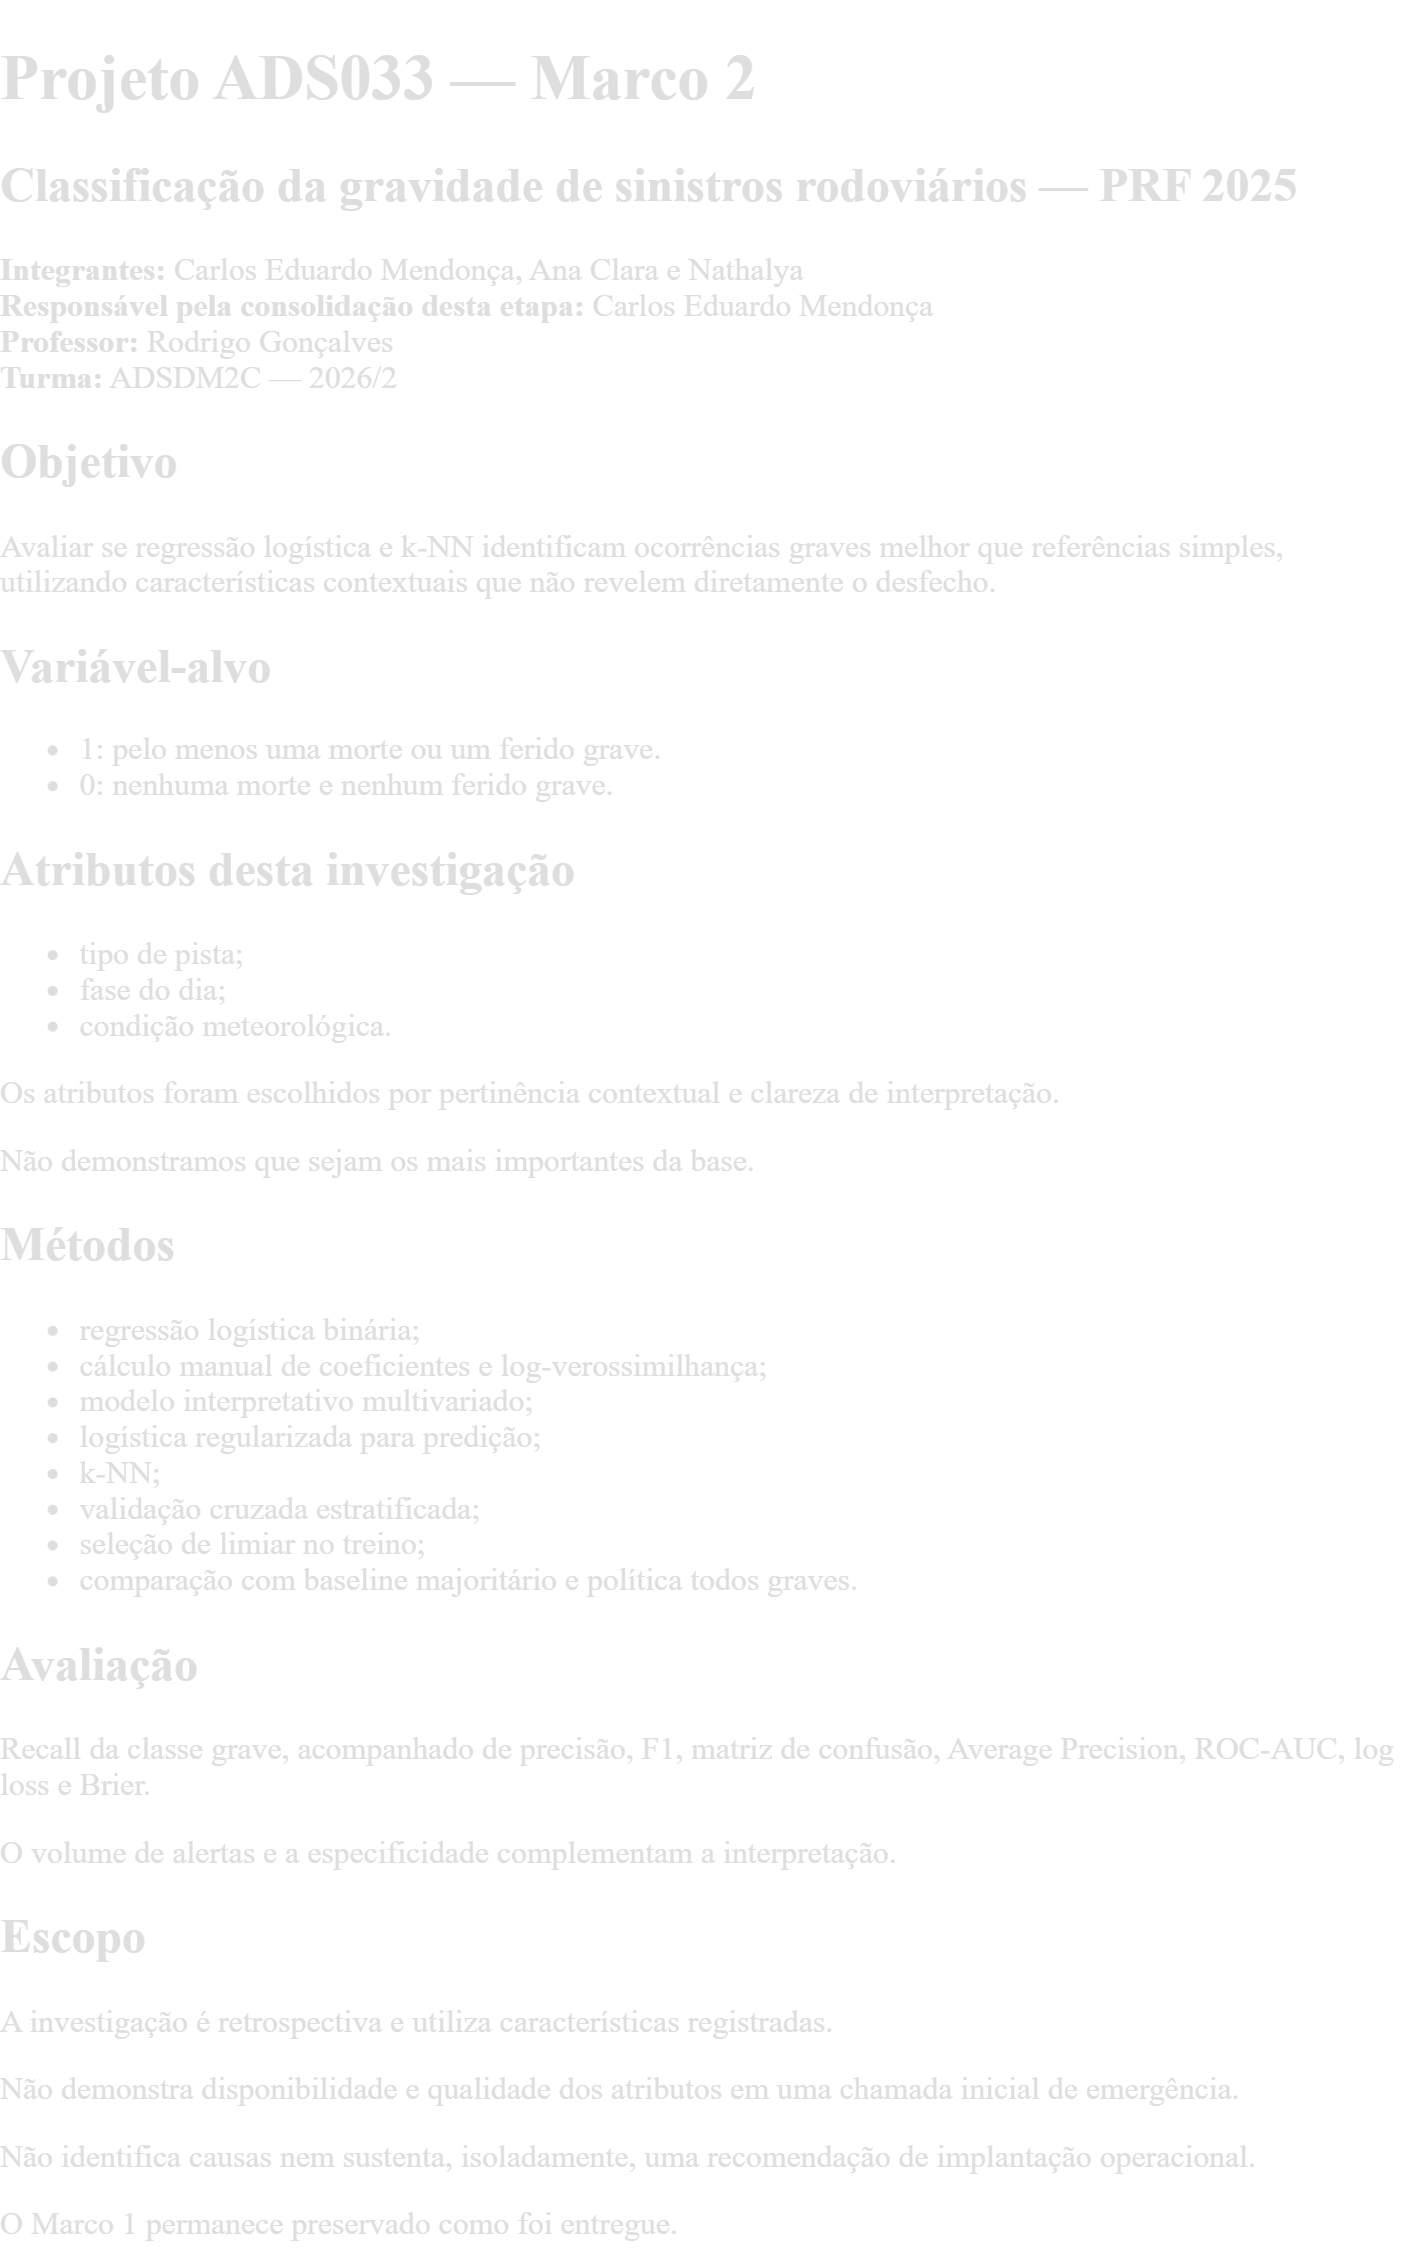

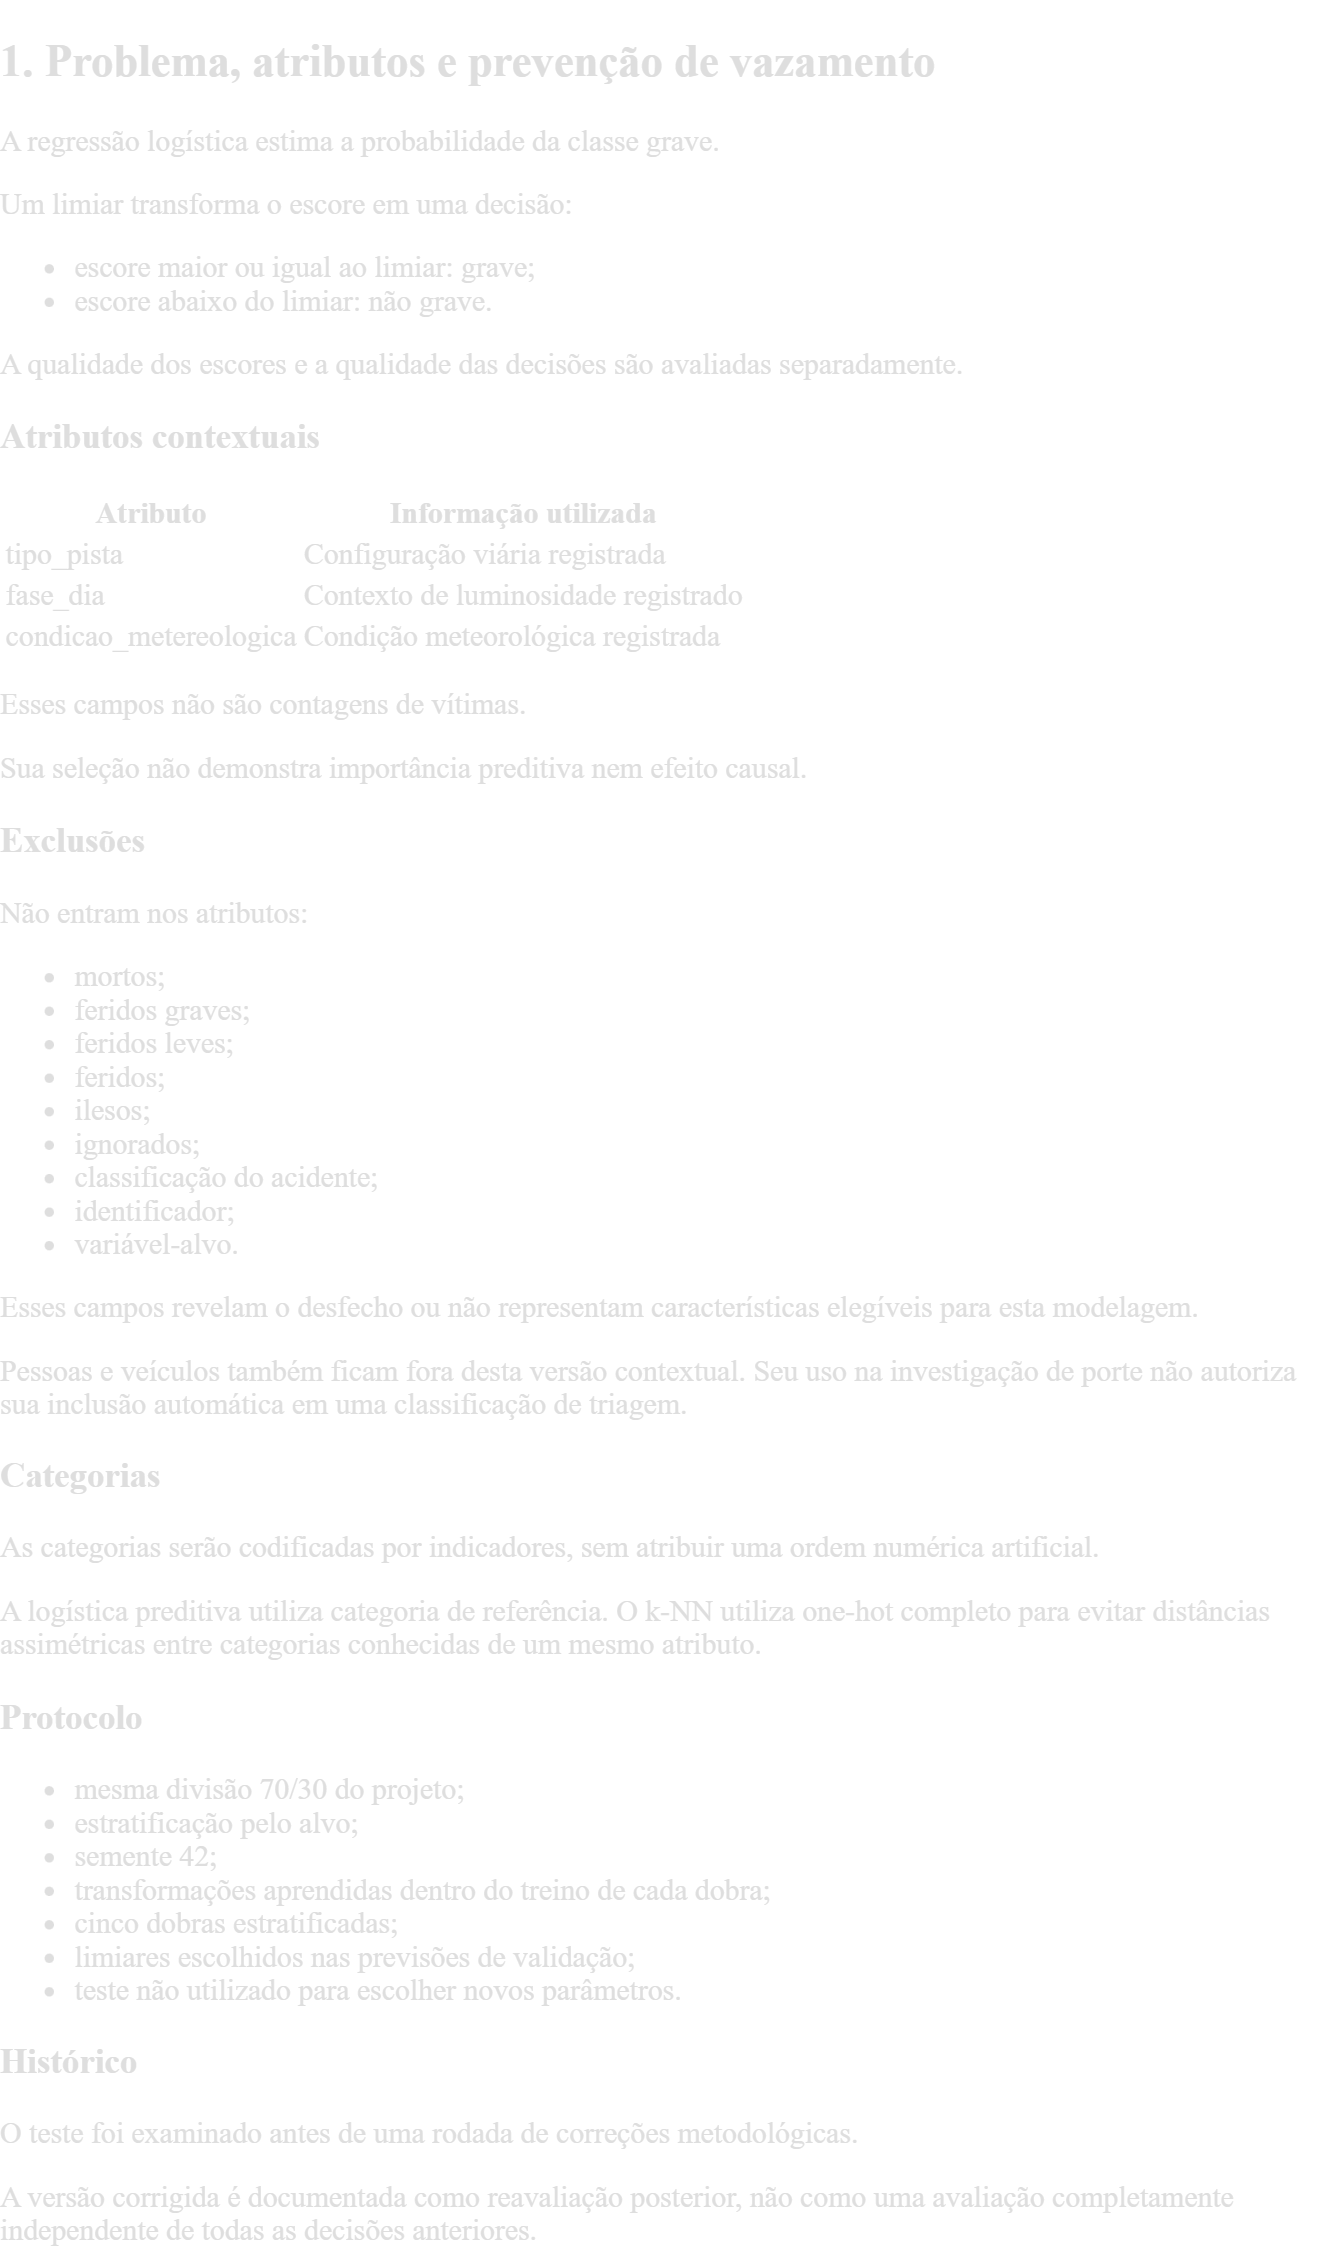

In [ ]:
# Importa ferramentas para verificar o arquivo.
import os

# Importa operações numéricas vetorizadas.
import numpy as np

# Importa leitura e manipulação de tabelas.
import pandas as pd

# Importa gráficos em escala linear.
import matplotlib.pyplot as plt

# Importa a exibição de tabelas no notebook.
from IPython.display import display

# Importa a divisão amostral e a validação estratificada.
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

# Importa o pipeline e a codificação nominal.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Importa os modelos.
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Importa as métricas de classificação e probabilidades.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

# Importa a implementação estatística para interpretação dos coeficientes.
import statsmodels.formula.api as smf

# Define a semente oficial.
RANDOM_STATE = 42

# Define os atributos contextuais desta primeira versão.
ATRIBUTOS = [
    "tipo_pista",
    "fase_dia",
    "condicao_metereologica"
]

# Configura a visualização das tabelas.
pd.set_option("display.max_columns", None)

# Confirma as escolhas.
print("Atributos:", ATRIBUTOS)
print("Semente:", RANDOM_STATE)

Atributos: ['tipo_pista', 'fase_dia', 'condicao_metereologica']
Semente: 42


In [ ]:
# Importa o acesso ao Drive.
from google.colab import drive

# Monta o Drive.
drive.mount("/content/drive", force_remount=False)

# Define o caminho oficial.
CAMINHO_BASE = "/content/drive/MyDrive/base_compartilhada/datatran2025.csv"

# Interrompe se o arquivo não existir.
if not os.path.isfile(CAMINHO_BASE):
    raise FileNotFoundError(CAMINHO_BASE)

# Lê a base com os parâmetros do projeto.
df = pd.read_csv(
    CAMINHO_BASE,
    sep=";",
    decimal=",",
    encoding="latin1",
    low_memory=False
)

# Confirma a versão consolidada.
assert df.shape == (72_529, 30), "Dimensão inesperada."

# Confirma a chave dos registros.
assert df["id"].notna().all() and df["id"].is_unique

# Confirma que os componentes do alvo estão preenchidos.
assert df[["mortos", "feridos_graves"]].notna().all().all()

# Constrói o alvo vetorialmente.
df["alvo_grave"] = (
    df["mortos"].gt(0) | df["feridos_graves"].gt(0)
).astype("int8")

# Define os campos proibidos.
PROIBIDAS = {
    "id", "mortos", "feridos_graves", "feridos_leves",
    "feridos", "ilesos", "ignorados",
    "classificacao_acidente", "alvo_grave"
}

# Confirma que os atributos não contêm os campos proibidos.
assert not PROIBIDAS.intersection(ATRIBUTOS)

# Separa atributos e resposta.
X = df[ATRIBUTOS].copy()
y = df["alvo_grave"].copy()

# Confirma a completude dos atributos desta versão.
assert X.notna().all().all(), (
    "Há ausências nos atributos. "
    "Interrompa e revise o tratamento antes de continuar."
)

# Reproduz a divisão do projeto.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Confirma as quantidades esperadas.
assert len(X_treino) == 50_770
assert len(X_teste) == 21_759

# Confirma que as partições não se sobrepõem.
assert X_treino.index.intersection(X_teste.index).empty

# Cria uma tabela de desenvolvimento para a análise interpretativa.
dados_treino = X_treino.copy()
dados_treino["alvo_grave"] = y_treino

# Mostra a distribuição das classes sem avaliar modelos no teste.
display(pd.DataFrame({
    "particao": ["Treino", "Teste"],
    "ocorrencias": [len(y_treino), len(y_teste)],
    "graves": [int(y_treino.sum()), int(y_teste.sum())],
    "graves_pct": [y_treino.mean() * 100, y_teste.mean() * 100]
}).round(3))

# Mostra a composição dos atributos apenas no treino.
for coluna in ATRIBUTOS:

    # Identifica a variável examinada.
    print("\nCategorias no treino:", coluna)

    # Exibe contagens sem transformar categorias em números ordinais.
    display(X_treino[coluna].value_counts(dropna=False).to_frame("ocorrencias"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,particao,ocorrencias,graves,graves_pct
0,Treino,50770,14345,28.255
1,Teste,21759,6148,28.255



Categorias no treino: tipo_pista


,ocorrencias
tipo_pista,
Simples,24250
Dupla,21579
Múltipla,4941



Categorias no treino: fase_dia


,ocorrencias
fase_dia,
Pleno dia,28240
Plena Noite,17379
Anoitecer,2745
Amanhecer,2406



Categorias no treino: condicao_metereologica


,ocorrencias
condicao_metereologica,
Céu Claro,32497
Nublado,7993
Chuva,4479
Sol,2921
Garoa/Chuvisco,1724
Ignorado,682
Nevoeiro/Neblina,395
Vento,78
Neve,1


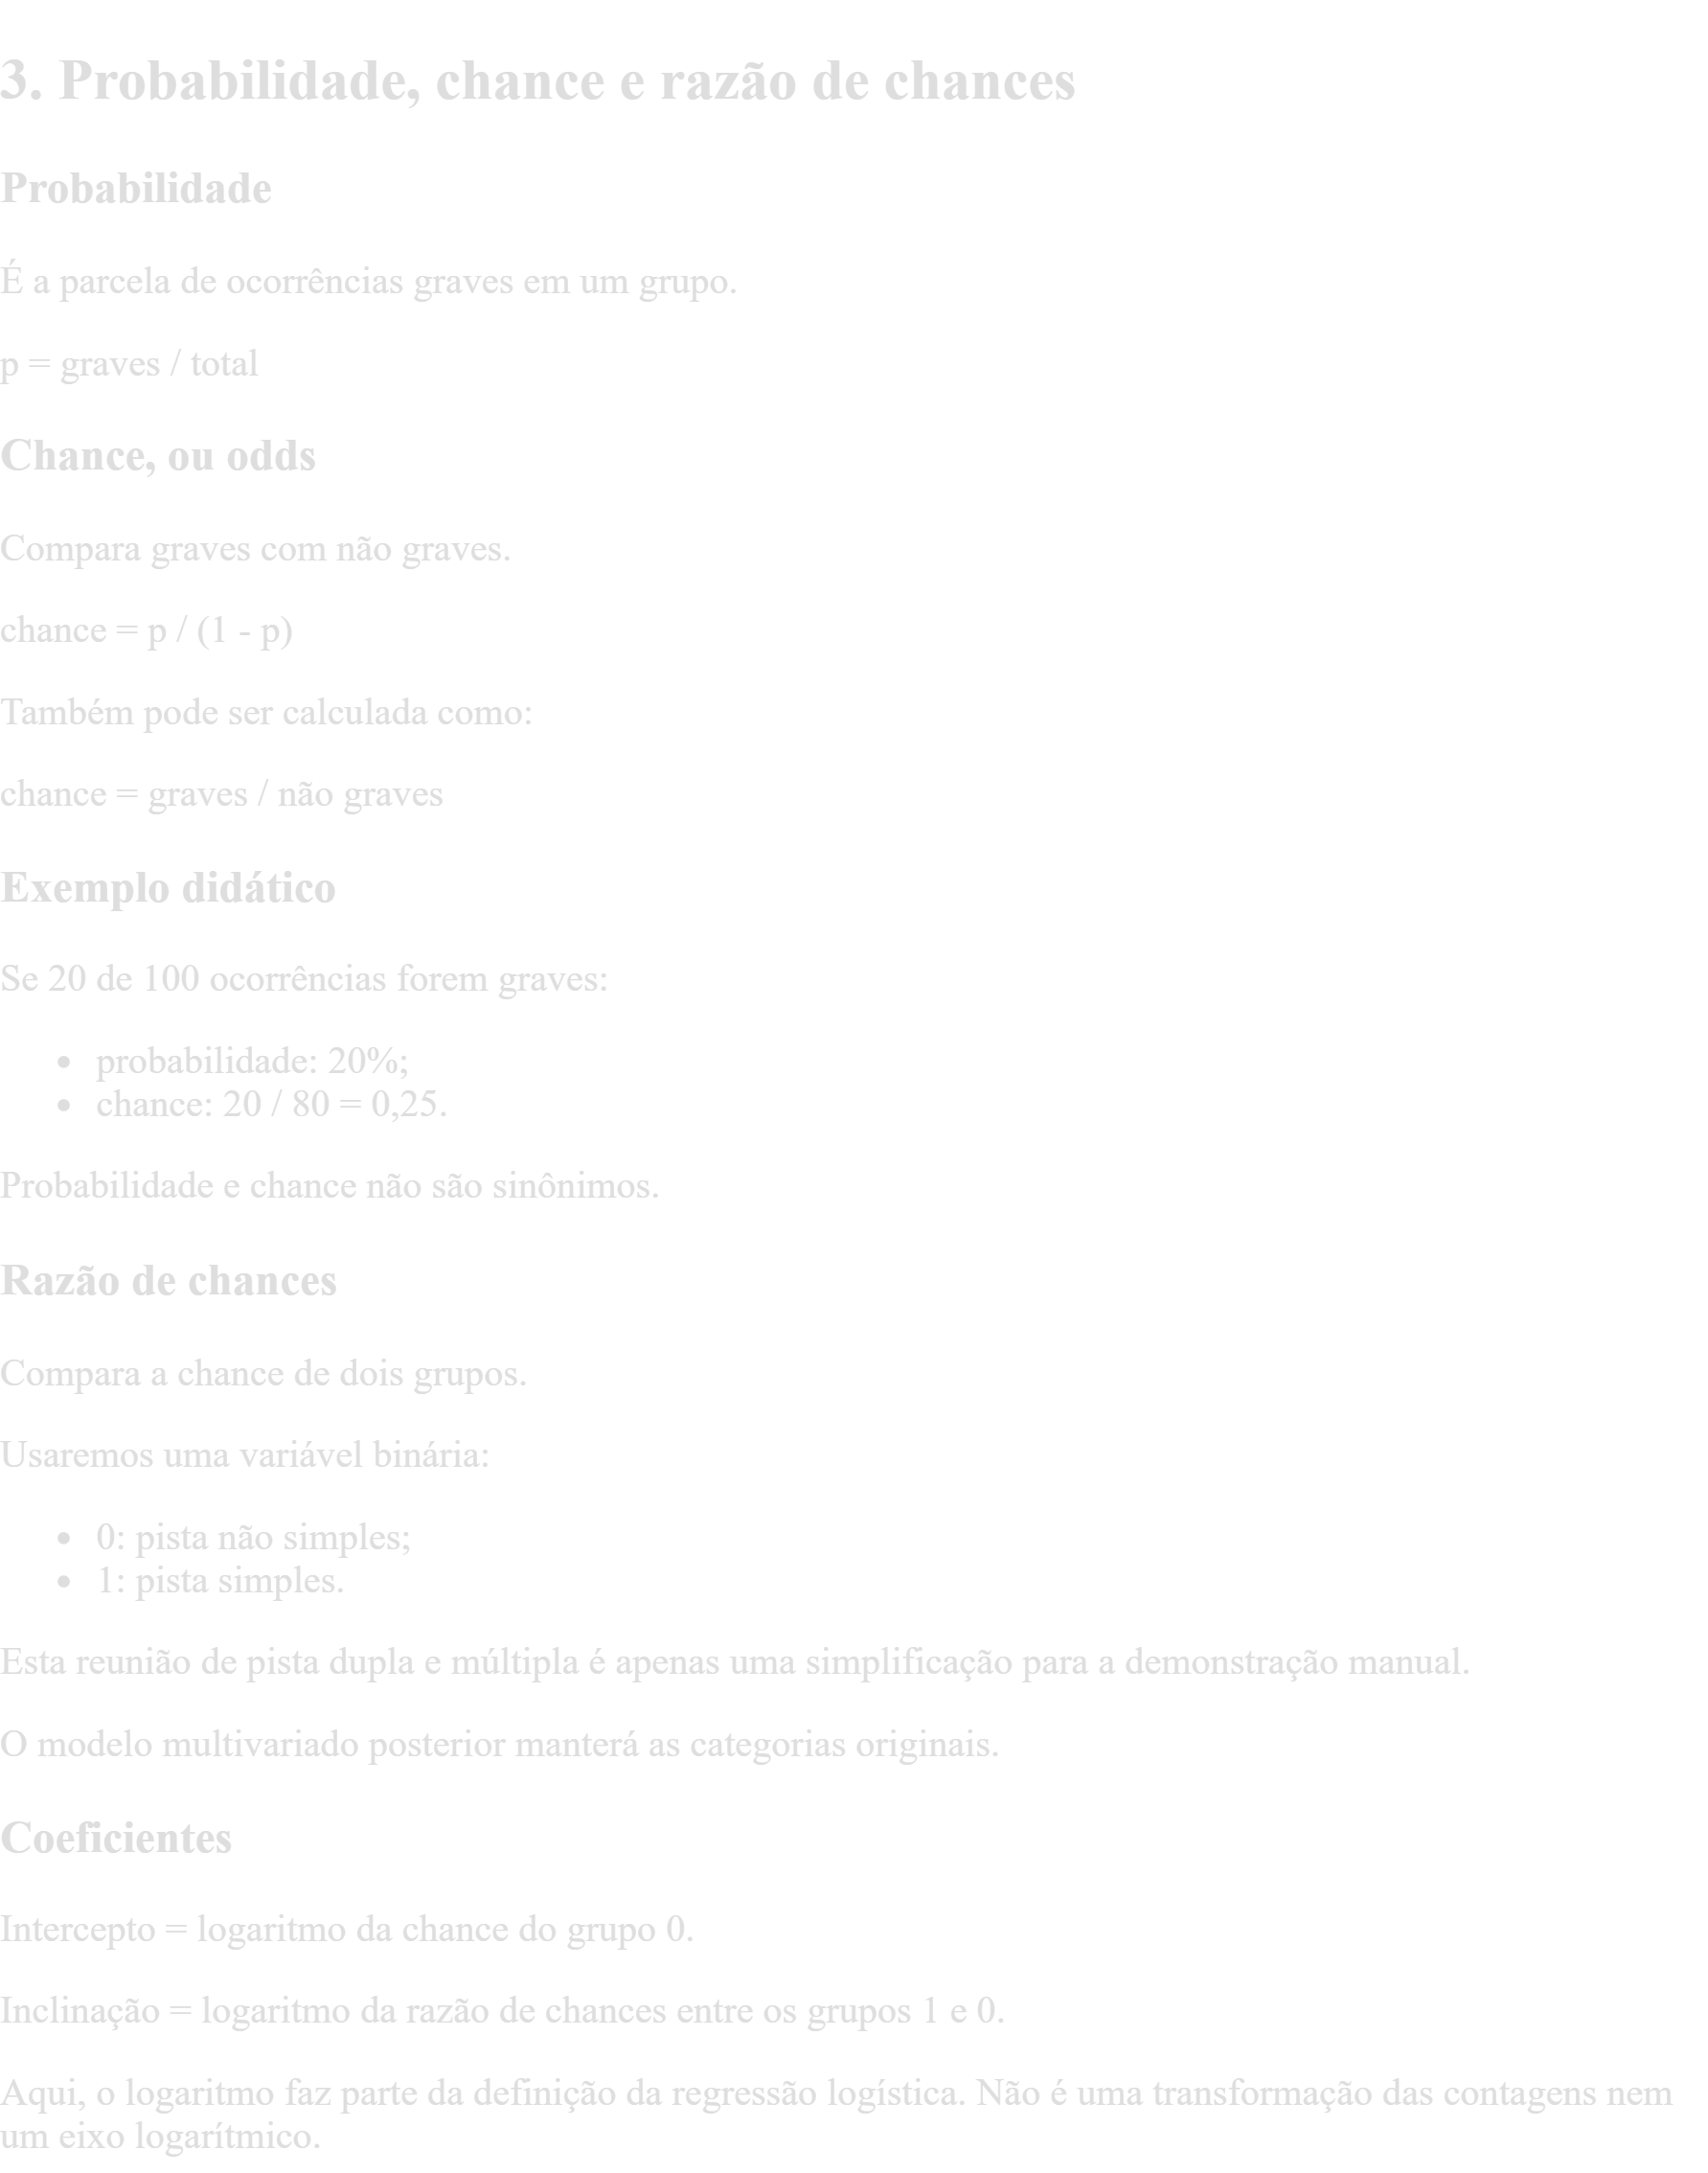

In [ ]:
# Cria uma cópia somente do treino para a demonstração manual.
didatica = dados_treino.copy()

# Cria o indicador binário de pista simples.
didatica["pista_simples"] = (
    didatica["tipo_pista"].eq("Simples")
).astype("int8")

# Conta graves e não graves nos dois grupos.
tabela_chances = pd.crosstab(
    didatica["pista_simples"],
    didatica["alvo_grave"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# Nomeia as colunas.
tabela_chances.columns = ["nao_graves", "graves"]

# Confirma que as quatro células são positivas.
assert tabela_chances[["nao_graves", "graves"]].gt(0).all().all(), (
    "Há célula zero. A conta manual exige revisão por separação."
)

# Calcula os totais.
tabela_chances["total"] = (
    tabela_chances["nao_graves"] + tabela_chances["graves"]
)

# Calcula probabilidades.
tabela_chances["probabilidade"] = (
    tabela_chances["graves"] / tabela_chances["total"]
)

# Calcula chances.
tabela_chances["chance"] = (
    tabela_chances["graves"] / tabela_chances["nao_graves"]
)

# Calcula os coeficientes manualmente.
beta0_manual = np.log(tabela_chances.loc[0, "chance"])

razao_chances_manual = (
    tabela_chances.loc[1, "chance"]
    / tabela_chances.loc[0, "chance"]
)

beta1_manual = np.log(razao_chances_manual)

# Calcula também a razão de probabilidades para mostrar a diferença.
razao_probabilidades = (
    tabela_chances.loc[1, "probabilidade"]
    / tabela_chances.loc[0, "probabilidade"]
)

# Exibe a tabela.
display(tabela_chances.round(5))

# Exibe os resultados sem confundir as duas razões.
print("Intercepto manual:", beta0_manual)
print("Coeficiente manual:", beta1_manual)
print("Razão de chances:", razao_chances_manual)
print("Razão de probabilidades:", razao_probabilidades)

# Ajusta o mesmo modelo sem penalização pelo statsmodels.
modelo_binario = smf.logit(
    "alvo_grave ~ pista_simples",
    data=didatica
).fit(disp=False)

# Confere os coeficientes.
assert np.isclose(
    beta0_manual,
    modelo_binario.params["Intercept"],
    atol=1e-5
)

assert np.isclose(
    beta1_manual,
    modelo_binario.params["pista_simples"],
    atol=1e-5
)

print("Conta manual conferida com statsmodels.")

,nao_graves,graves,total,probabilidade,chance
pista_simples,,,,,
0,20280,6240,26520,0.23529,0.30769
1,16145,8105,24250,0.33423,0.50201


Intercepto manual: -1.1786549963416462
Coeficiente manual: 0.48952574731904697
Razão de chances: 1.631542273149582
Razão de probabilidades: 1.4204639175257734
Conta manual conferida com statsmodels.


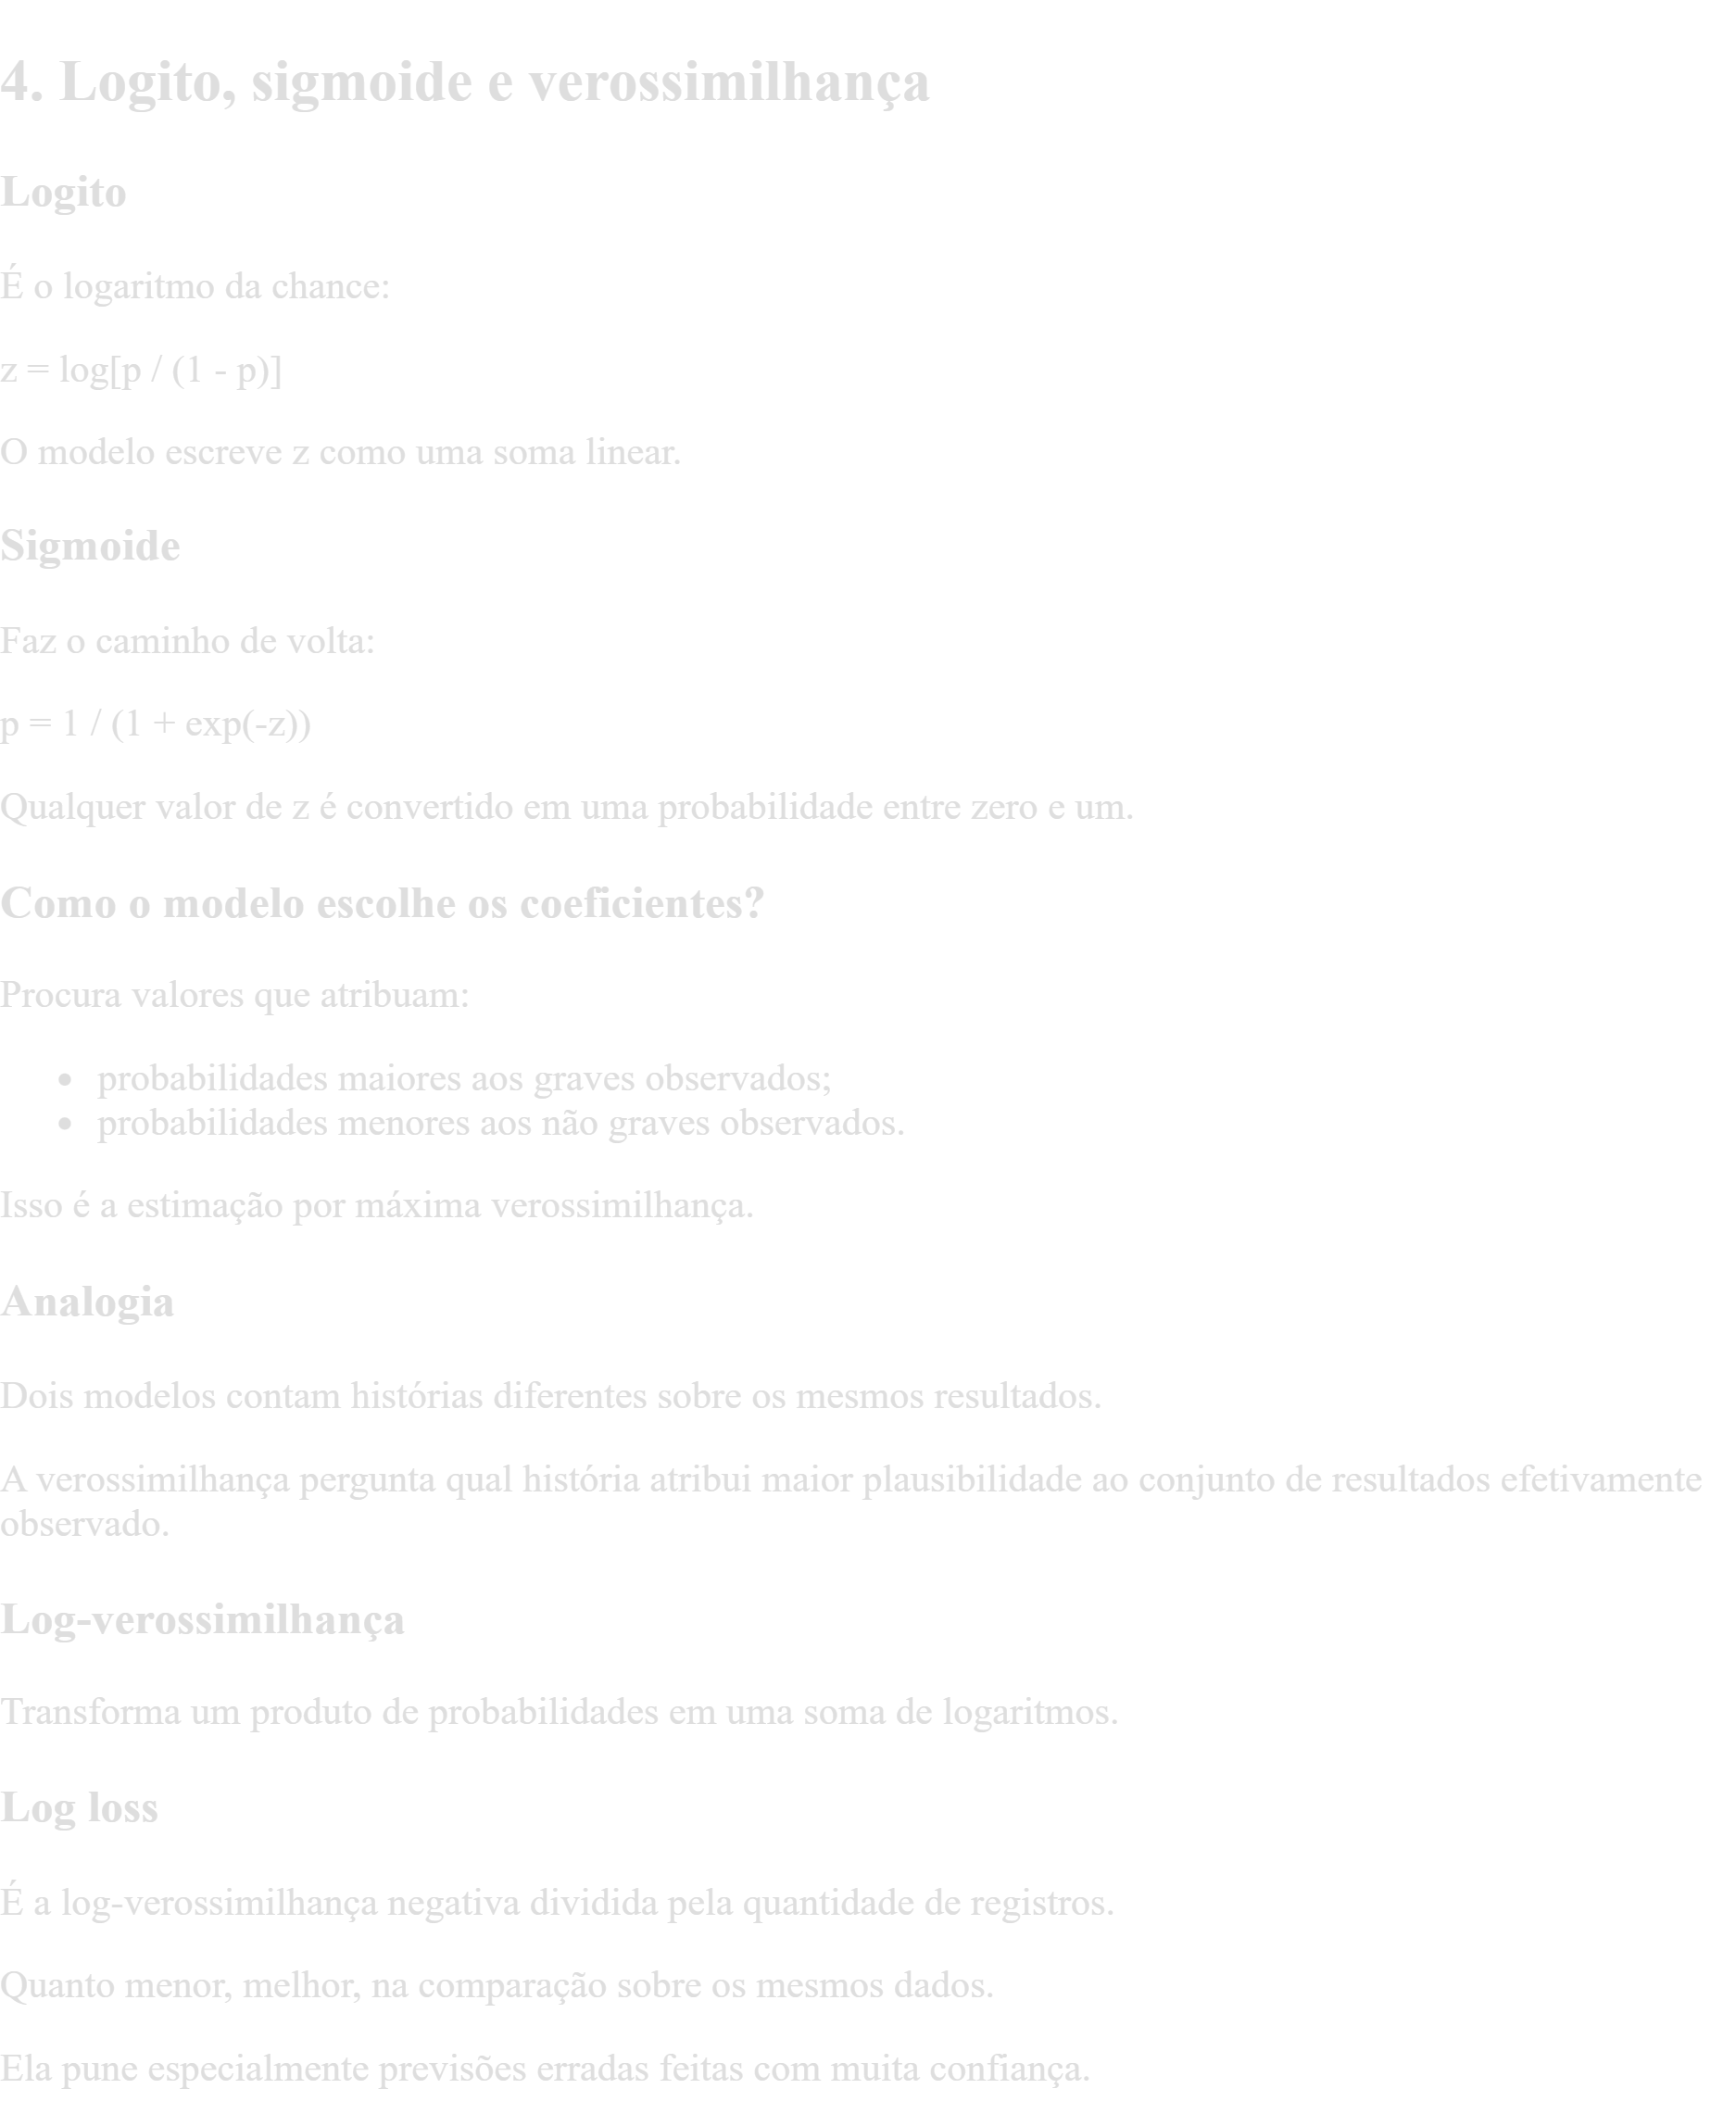

,medida,valor
0,Log-verossimilhança nula,-30225.636791
1,Log-verossimilhança com pista simples,-29919.611334
2,Pseudo-R² de McFadden,0.010125
3,Log loss no treino didático,0.589317


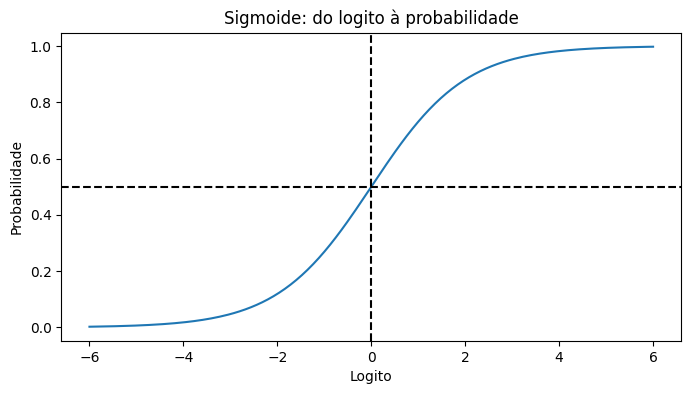

In [ ]:
# Define a função que transforma logito em probabilidade.
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


# Obtém os vetores da demonstração.
x_binario = didatica["pista_simples"].to_numpy(dtype=float)
y_binario = didatica["alvo_grave"].to_numpy(dtype=float)

# Calcula os logitos usando os coeficientes manuais.
z_manual = beta0_manual + beta1_manual * x_binario

# Converte os logitos em probabilidades.
p_manual = sigmoide(z_manual)

# Protege o cálculo numérico de logaritmos de zero.
epsilon = np.finfo(float).eps
p_seguro = np.clip(p_manual, epsilon, 1 - epsilon)

# Calcula a log-verossimilhança vetorialmente.
ll_manual = np.sum(
    y_binario * np.log(p_seguro)
    + (1 - y_binario) * np.log(1 - p_seguro)
)

# Calcula a probabilidade constante do modelo nulo.
p_nulo = y_binario.mean()

# Calcula a log-verossimilhança do modelo nulo.
ll_nulo = np.sum(
    y_binario * np.log(p_nulo)
    + (1 - y_binario) * np.log(1 - p_nulo)
)

# Calcula o pseudo-R² de McFadden.
pseudo_r2_manual = 1 - ll_manual / ll_nulo

# Confere a log-verossimilhança com a biblioteca.
assert np.isclose(ll_manual, modelo_binario.llf)

# Confere a relação com log loss.
assert np.isclose(
    -ll_manual / len(y_binario),
    log_loss(y_binario, p_manual)
)

# Exibe os resultados.
display(pd.DataFrame({
    "medida": [
        "Log-verossimilhança nula",
        "Log-verossimilhança com pista simples",
        "Pseudo-R² de McFadden",
        "Log loss no treino didático"
    ],
    "valor": [
        ll_nulo,
        ll_manual,
        pseudo_r2_manual,
        -ll_manual / len(y_binario)
    ]
}))

# Mostra a sigmoide sem ajustar outro modelo.
grade_z = np.linspace(-6, 6, 200)

plt.figure(figsize=(8, 4))
plt.plot(grade_z, sigmoide(grade_z))
plt.axhline(0.5, linestyle="--", color="black")
plt.axvline(0, linestyle="--", color="black")
plt.xlabel("Logito")
plt.ylabel("Probabilidade")
plt.title("Sigmoide: do logito à probabilidade")
plt.show()

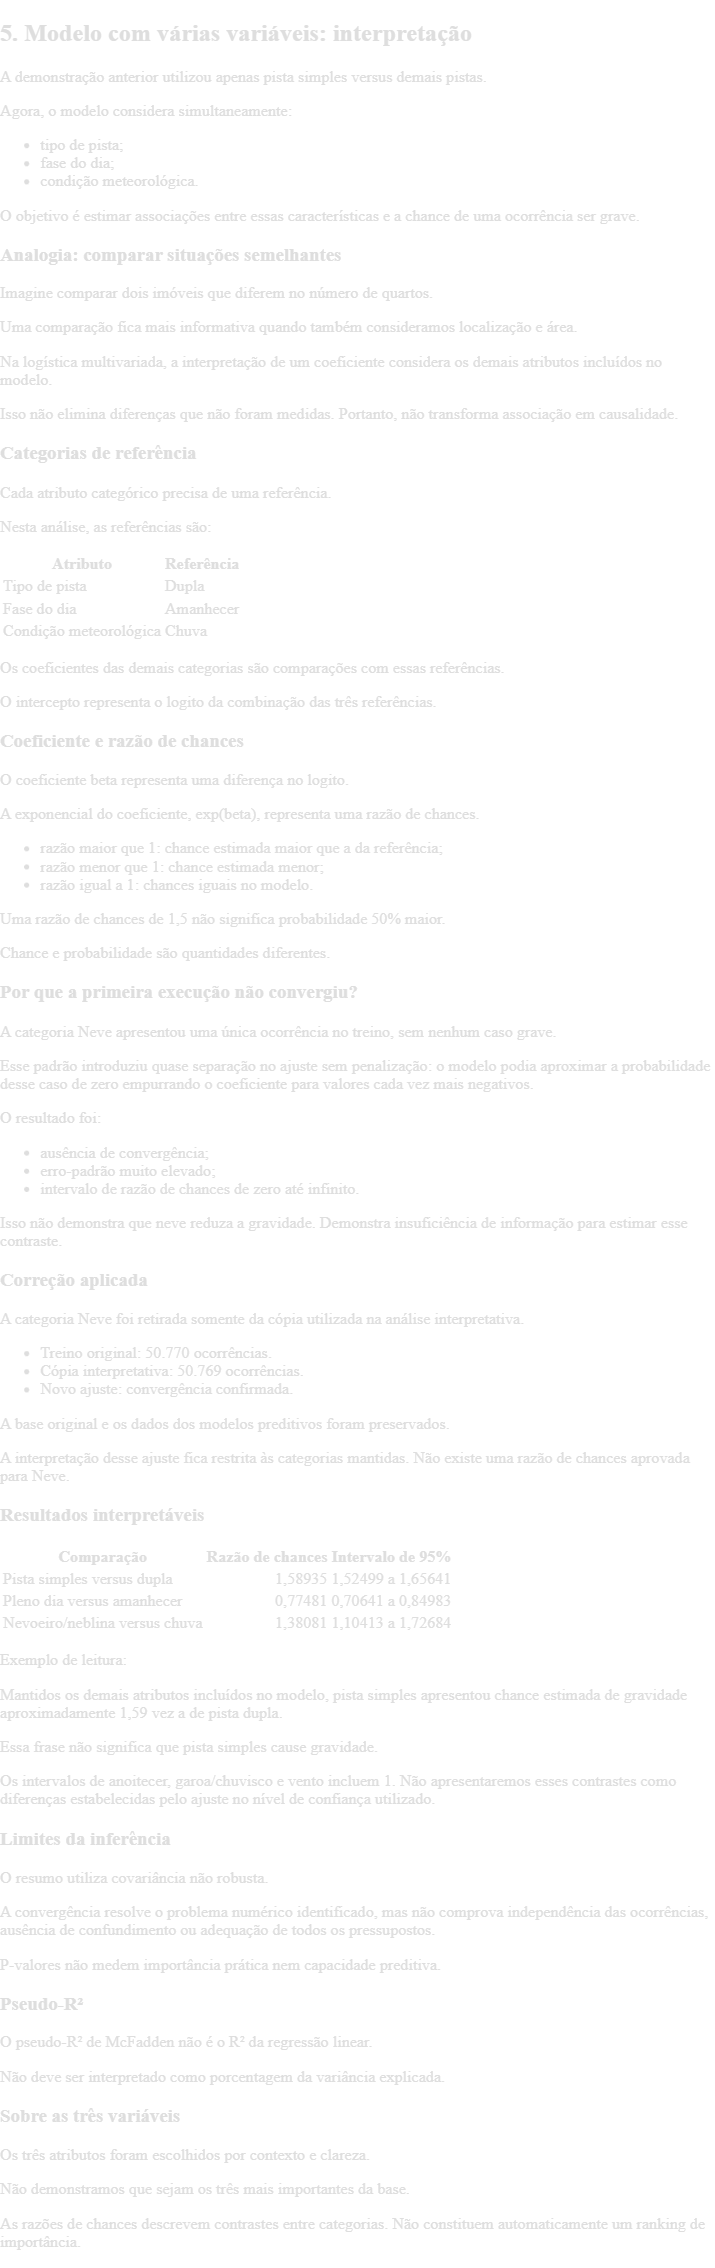

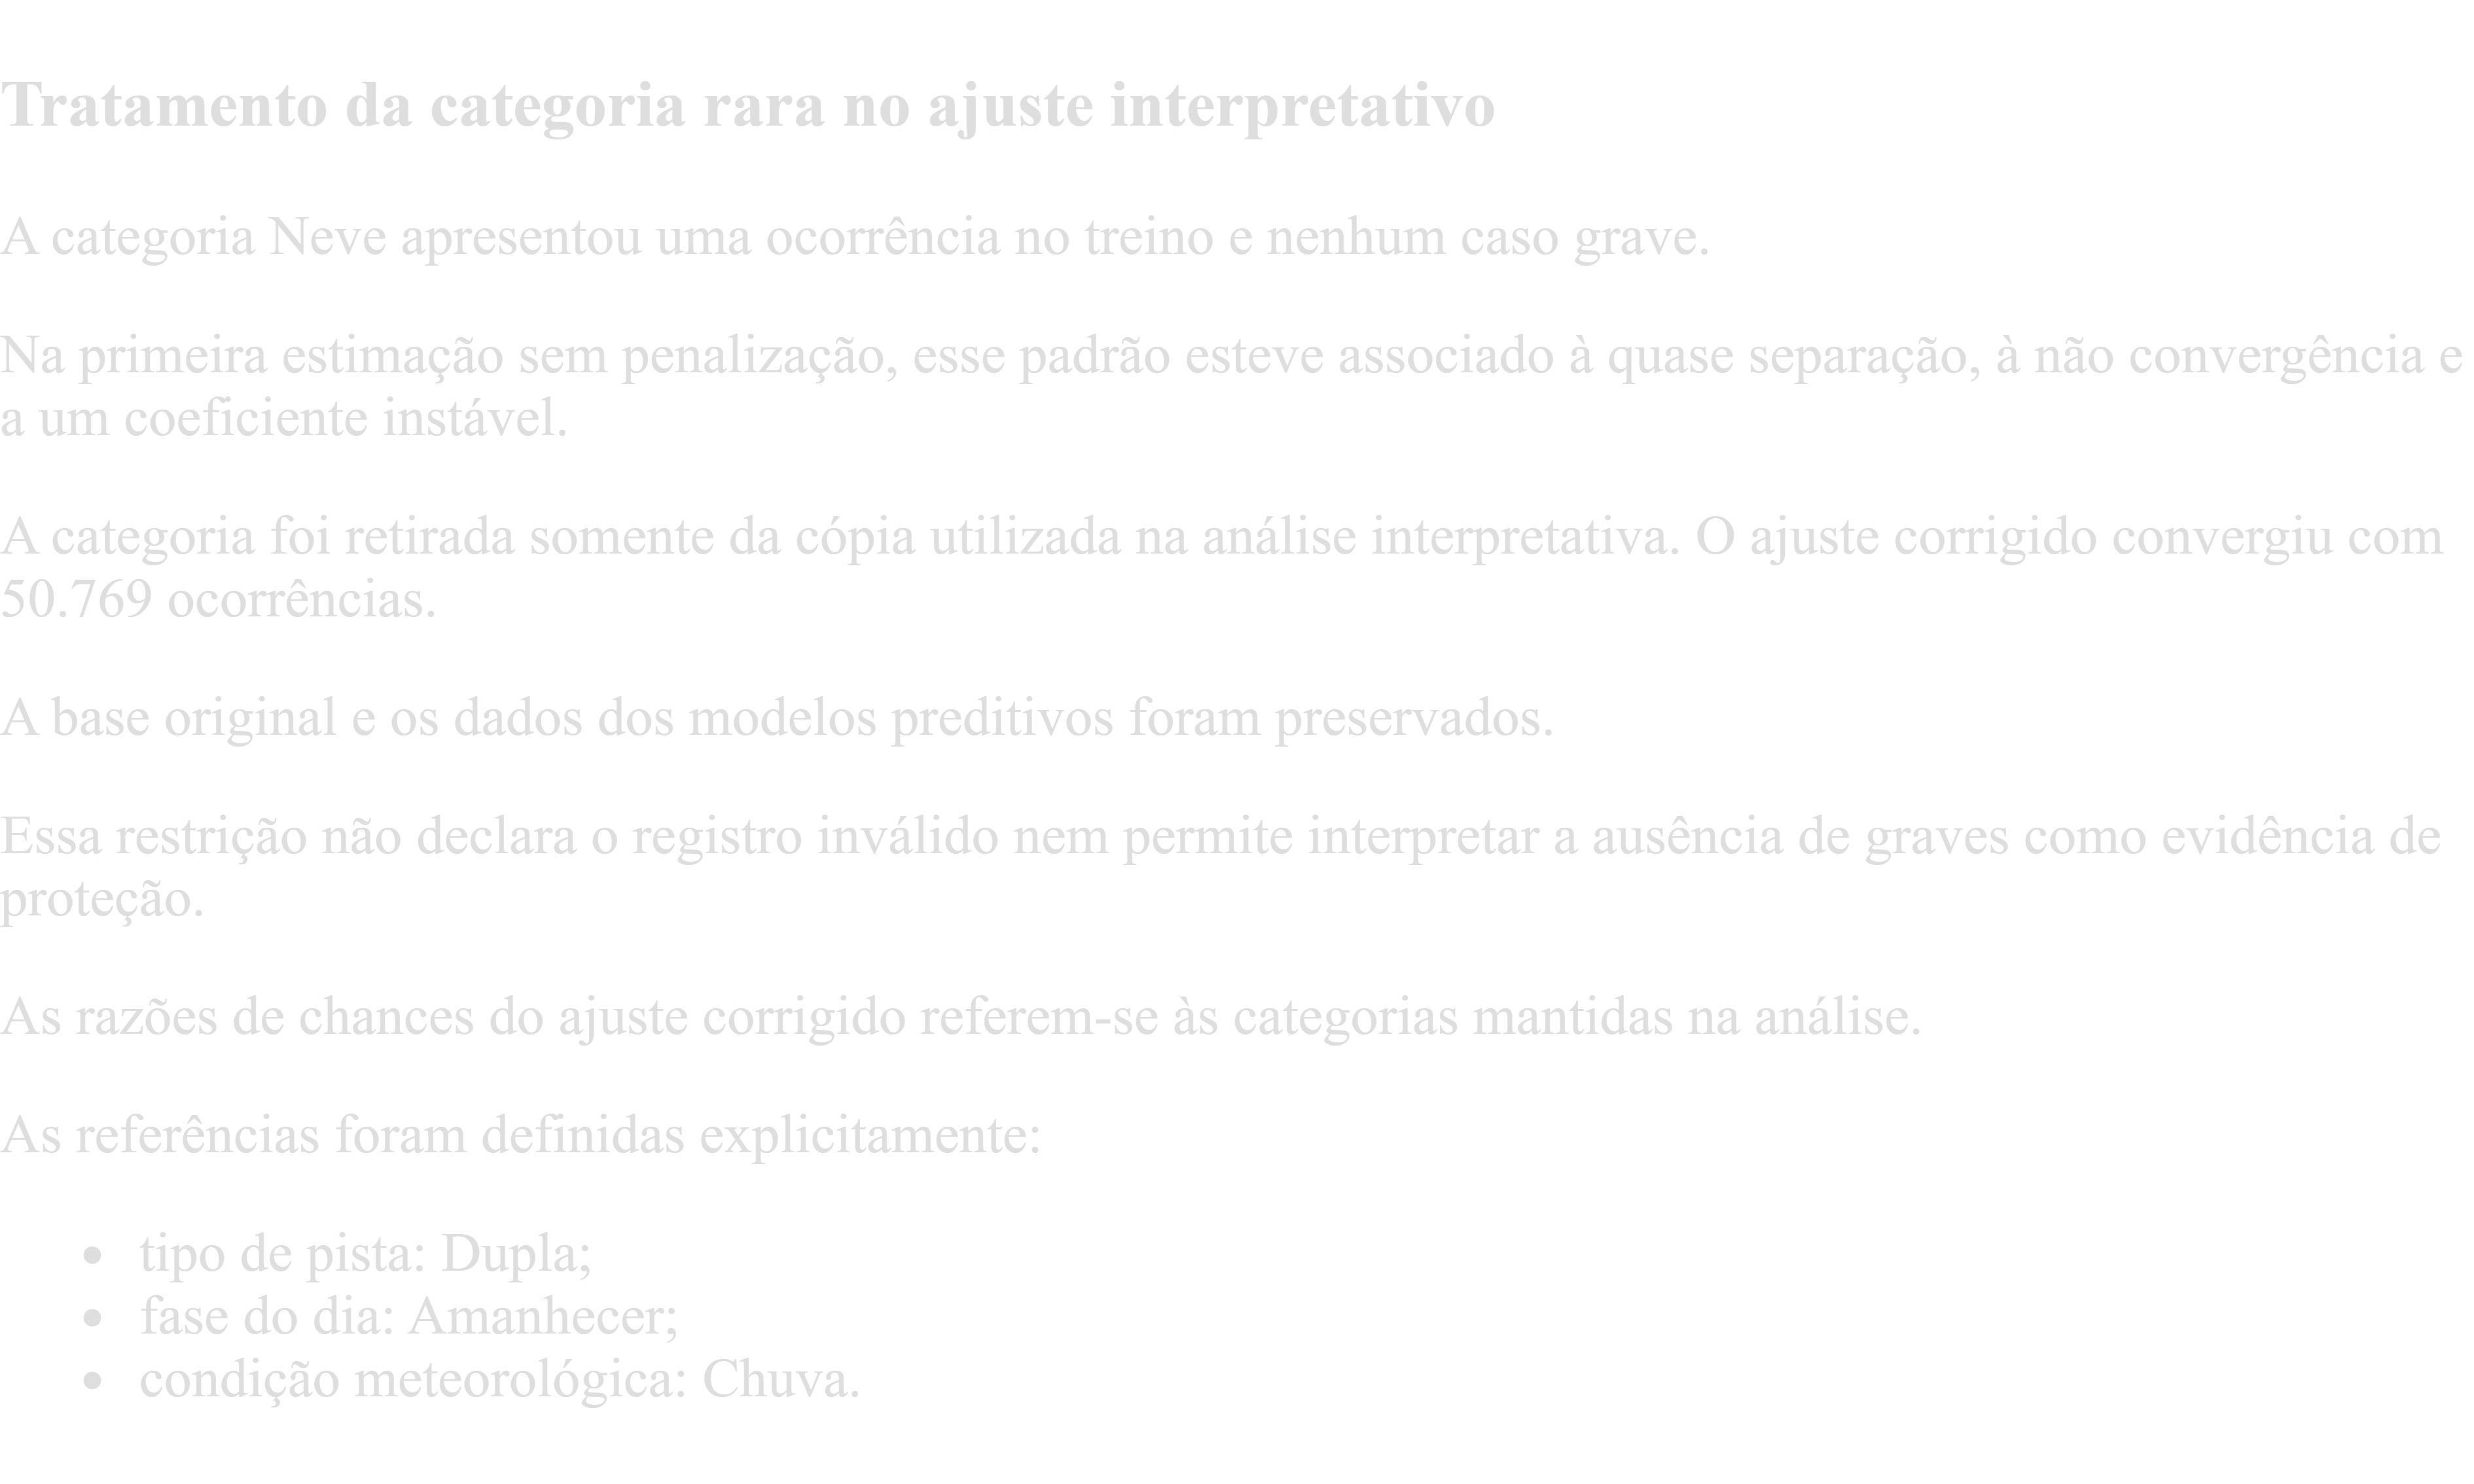

In [ ]:
# Mostra o suporte das categorias no treino original.
for coluna in ATRIBUTOS:

    # Identifica o atributo.
    print("\nSuporte no treino original:", coluna)

    # Exibe graves e não graves por categoria.
    display(pd.crosstab(
        dados_treino[coluna],
        dados_treino["alvo_grave"]
    ))


# Identifica a categoria cujo contraste não pôde ser estimado adequadamente.
mascara_neve = dados_treino["condicao_metereologica"].eq("Neve")

# Registra quantas ocorrências serão retiradas apenas da cópia interpretativa.
print(
    "\nOcorrências de Neve fora da análise interpretativa:",
    int(mascara_neve.sum())
)

# Cria uma cópia sem modificar os dados usados na predição.
dados_interpretacao = dados_treino.loc[~mascara_neve].copy()

# Confirma que a cópia continua contendo as duas classes.
assert dados_interpretacao["alvo_grave"].nunique() == 2

# Confirma a presença das categorias de referência.
assert dados_interpretacao["tipo_pista"].eq("Dupla").any()
assert dados_interpretacao["fase_dia"].eq("Amanhecer").any()
assert dados_interpretacao["condicao_metereologica"].eq("Chuva").any()

# Declara as referências diretamente na fórmula.
FORMULA_INTERPRETATIVA = (
    'alvo_grave ~ C(tipo_pista, Treatment(reference="Dupla"))'
    ' + C(fase_dia, Treatment(reference="Amanhecer"))'
    ' + C(condicao_metereologica, Treatment(reference="Chuva"))'
)

# Informa o tamanho da análise interpretativa.
print("Ocorrências no treino original:", len(dados_treino))
print("Ocorrências na cópia interpretativa:", len(dados_interpretacao))

# Ajusta o modelo sem penalização somente na cópia do treino.
modelo_interpretativo = smf.logit(
    FORMULA_INTERPRETATIVA,
    data=dados_interpretacao
).fit(
    disp=False,
    maxiter=200
)

# Recupera a indicação de convergência.
convergiu = bool(
    modelo_interpretativo.mle_retvals.get("converged", False)
)

# Informa o estado antes de interpretar os resultados.
print("Convergência:", convergiu)

# Interrompe a execução se o ajuste não tiver convergido.
assert convergiu, (
    "A estimação não convergiu. "
    "Os coeficientes e intervalos não estão aprovados para interpretação."
)
# Recupera os coeficientes e intervalos.
coeficientes = modelo_interpretativo.params
intervalos = modelo_interpretativo.conf_int()

# Confirma que as estimativas são finitas.
assert np.isfinite(coeficientes.to_numpy()).all(), (
    "Existem coeficientes não finitos."
)

assert np.isfinite(intervalos.to_numpy()).all(), (
    "Existem limites não finitos."
)

# Confirma que a exponenciação não ultrapassará a capacidade numérica.
limite_exponencial = np.log(np.finfo(float).max)

assert intervalos.to_numpy().max() < limite_exponencial, (
    "Há intervalos excessivamente grandes. "
    "O ajuste exige revisão antes da interpretação."
)

# Constrói as razões de chances e seus intervalos.
tabela_razoes_chances = pd.DataFrame({
    "beta": coeficientes,
    "razao_chances": np.exp(coeficientes),
    "IC95_inferior": np.exp(intervalos[0]),
    "IC95_superior": np.exp(intervalos[1]),
    "p_valor": modelo_interpretativo.pvalues
})

# Exibe o resumo do ajuste convergido.
print(modelo_interpretativo.summary())

# Exibe a tabela interpretativa.
display(tabela_razoes_chances.round(5))

# Mostra as referências sem consultar metadados internos da biblioteca.
display(pd.DataFrame({
    "atributo": ATRIBUTOS,
    "referencia": ["Dupla", "Amanhecer", "Chuva"]
}))

# Confirma que os dados preditivos continuam preservados.
assert len(dados_treino) == len(X_treino)

print("A restrição foi aplicada somente à análise interpretativa.")


Suporte no treino original: tipo_pista


alvo_grave,0,1
tipo_pista,,
Dupla,16445,5134
Múltipla,3835,1106
Simples,16145,8105



Suporte no treino original: fase_dia


alvo_grave,0,1
fase_dia,,
Amanhecer,1668,738
Anoitecer,1956,789
Plena Noite,11694,5685
Pleno dia,21107,7133



Suporte no treino original: condicao_metereologica


alvo_grave,0,1
condicao_metereologica,,
Chuva,3417,1062
Céu Claro,23048,9449
Garoa/Chuvisco,1310,414
Ignorado,468,214
Neve,1,0
Nevoeiro/Neblina,264,131
Nublado,5712,2281
Sol,2151,770
Vento,54,24



Ocorrências de Neve fora da análise interpretativa: 1
Ocorrências no treino original: 50770
Ocorrências na cópia interpretativa: 50769
Convergência: True
                           Logit Regression Results                           
Dep. Variable:             alvo_grave   No. Observations:                50769
Model:                          Logit   Df Residuals:                    50756
Method:                           MLE   Df Model:                           12
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                 0.01610
Time:                        02:36:53   Log-Likelihood:                -29739.
converged:                       True   LL-Null:                       -30225.
Covariance Type:            nonrobust   LLR p-value:                9.722e-201
                                                                                  coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------

,beta,razao_chances,IC95_inferior,IC95_superior,p_valor
Intercept,-1.29218,0.27467,0.24543,0.30740,0.00000
"C(tipo_pista, Treatment(reference=""Dupla""))[T.Múltipla]",-0.08439,0.91907,0.85341,0.98978,0.02565
"C(tipo_pista, Treatment(reference=""Dupla""))[T.Simples]",0.46332,1.58935,1.52499,1.65641,0.00000
"C(fase_dia, Treatment(reference=""Amanhecer""))[T.Anoitecer]",-0.07461,0.92810,0.82223,1.04762,0.22733
"C(fase_dia, Treatment(reference=""Amanhecer""))[T.Plena Noite]",0.11104,1.11744,1.01777,1.22687,0.01983
"C(fase_dia, Treatment(reference=""Amanhecer""))[T.Pleno dia]",-0.25514,0.77481,0.70641,0.84983,0.00000
"C(condicao_metereologica, Treatment(reference=""Chuva""))[T.Céu Claro]",0.27261,1.31339,1.22028,1.41361,0.00000
"C(condicao_metereologica, Treatment(reference=""Chuva""))[T.Garoa/Chuvisco]",-0.01447,0.98564,0.86438,1.12391,0.82899
"C(condicao_metereologica, Treatment(reference=""Chuva""))[T.Ignorado]",0.21164,1.23571,1.03447,1.47609,0.01961
"C(condicao_metereologica, Treatment(reference=""Chuva""))[T.Nevoeiro/Neblina]",0.32267,1.38081,1.10413,1.72684,0.00468


,atributo,referencia
0,tipo_pista,Dupla
1,fase_dia,Amanhecer
2,condicao_metereologica,Chuva


A restrição foi aplicada somente à análise interpretativa.


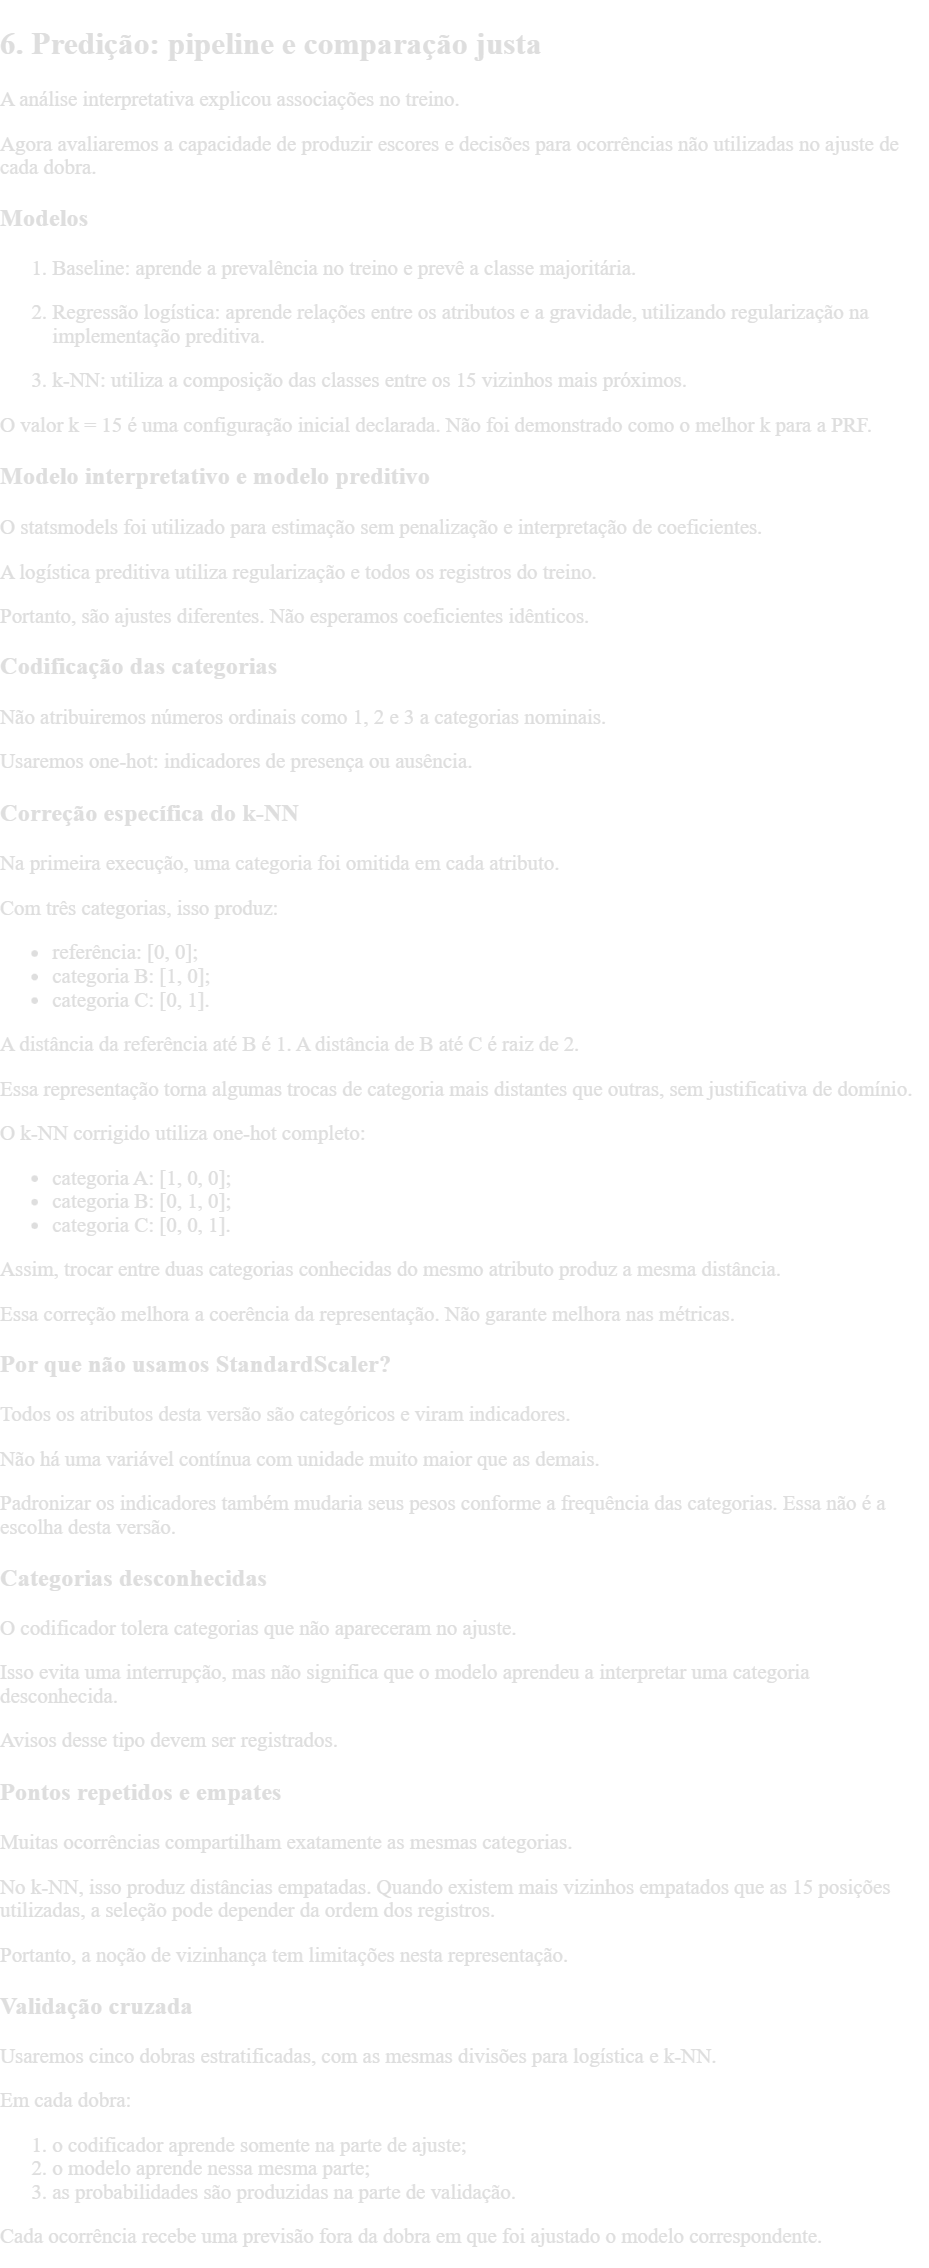

In [ ]:
# Cria o codificador da logística com categoria de referência.
codificador_logistica = OneHotEncoder(
    drop="first",
    handle_unknown="ignore"
)

# Cria o codificador completo do k-NN para evitar assimetria entre categorias.
codificador_knn = OneHotEncoder(
    drop=None,
    handle_unknown="ignore"
)

# Mantém a configuração da logística preditiva.
pipeline_logistica = Pipeline([
    ("categorias", codificador_logistica),
    ("modelo", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Corrige somente a representação do k-NN.
pipeline_knn = Pipeline([
    ("categorias", codificador_knn),
    ("modelo", KNeighborsClassifier(
        n_neighbors=15,
        weights="uniform",
        n_jobs=1
    ))
])

# Reproduz as cinco dobras estratificadas.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Usa as mesmas divisões nos dois modelos.
dobras = list(cv.split(X_treino, y_treino))

# Calcula probabilidades fora da dobra para a logística.
p_oof_logistica = cross_val_predict(
    pipeline_logistica,
    X_treino,
    y_treino,
    cv=dobras,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Calcula probabilidades fora da dobra para o k-NN corrigido.
p_oof_knn = cross_val_predict(
    pipeline_knn,
    X_treino,
    y_treino,
    cv=dobras,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Confirma a quantidade de probabilidades.
assert len(p_oof_logistica) == len(y_treino)
assert len(p_oof_knn) == len(y_treino)

# Confirma que as probabilidades são finitas.
assert np.isfinite(p_oof_logistica).all()
assert np.isfinite(p_oof_knn).all()

# Confirma os limites probabilísticos.
assert ((p_oof_logistica >= 0) & (p_oof_logistica <= 1)).all()
assert ((p_oof_knn >= 0) & (p_oof_knn <= 1)).all()

print("Validação concluída com one-hot completo no k-NN.")

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Validação concluída com one-hot completo no k-NN.


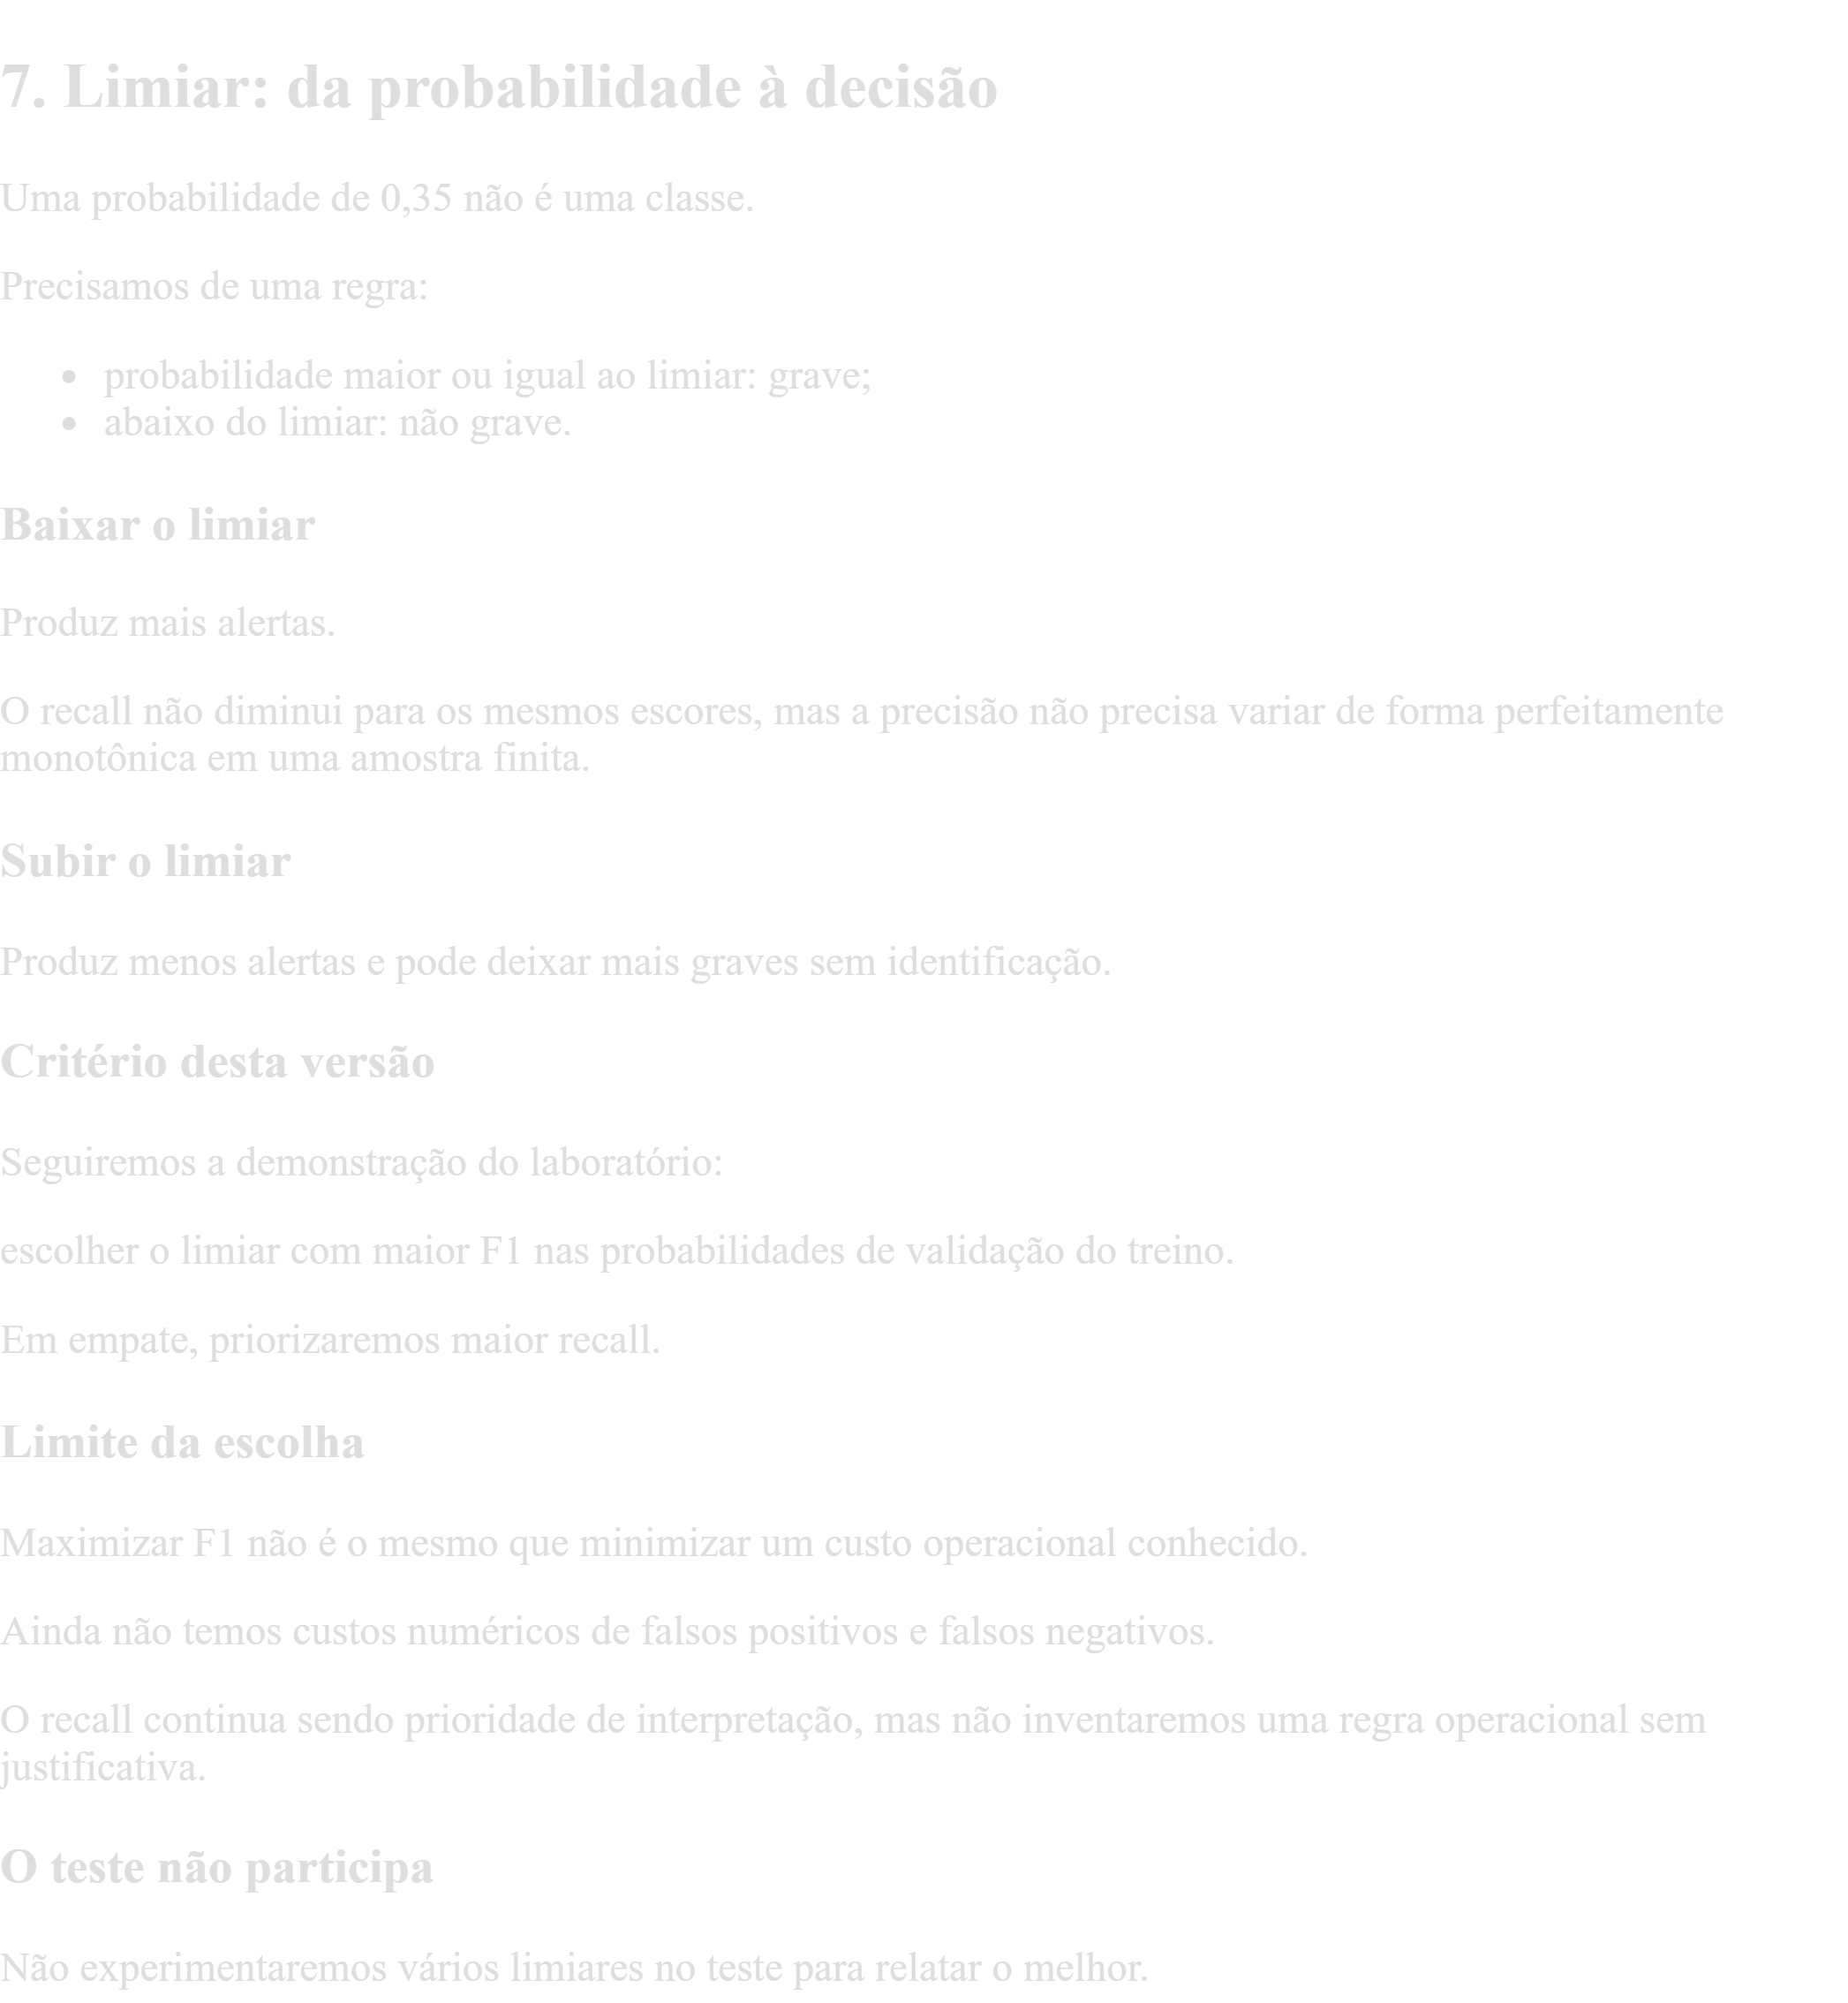

In [ ]:
# Define uma função de métricas para escores e decisões.
def avaliar_classificacao(y_real, probabilidades, limiar):

    # Converte escores em classes pela regra explícita.
    previsoes = (np.asarray(probabilidades) >= limiar).astype(int)

    # Retorna as métricas.
    return {
        "acuracia": accuracy_score(y_real, previsoes),
        "precisao": precision_score(y_real, previsoes, zero_division=0),
        "recall": recall_score(y_real, previsoes, zero_division=0),
        "F1": f1_score(y_real, previsoes, zero_division=0),
        "AP": average_precision_score(y_real, probabilidades),
        "ROC_AUC": roc_auc_score(y_real, probabilidades),
        "log_loss": log_loss(y_real, probabilidades, labels=[0, 1]),
        "Brier": brier_score_loss(y_real, probabilidades)
    }


# Define a grade antes de observar o teste.
LIMIARES = np.round(np.arange(0.10, 0.71, 0.05), 2)

# Reserva as tabelas e os limiares escolhidos.
tabelas_limiares = {}
limiares_escolhidos = {}

# Percorre os dois modelos, não as linhas da base.
for nome, probabilidades in {
    "Logistica": p_oof_logistica,
    "kNN": p_oof_knn
}.items():

    # Reserva os resultados da grade.
    linhas = []

    # Percorre limiares candidatos.
    for limiar in LIMIARES:

        # Calcula as métricas na validação do treino.
        resultado = avaliar_classificacao(
            y_treino,
            probabilidades,
            float(limiar)
        )

        # Registra o limiar.
        resultado["limiar"] = float(limiar)

        # Guarda o resultado.
        linhas.append(resultado)

    # Organiza e ordena pelos critérios declarados.
    tabela = pd.DataFrame(linhas).sort_values(
        ["F1", "recall", "limiar"],
        ascending=[False, False, True]
    )

    # Guarda a tabela.
    tabelas_limiares[nome] = tabela

    # Escolhe o limiar sem consultar o teste.
    limiares_escolhidos[nome] = float(tabela.iloc[0]["limiar"])

    # Exibe a análise.
    print("\nModelo:", nome)
    display(tabela[["limiar", "precisao", "recall", "F1"]].round(4))
    print("Limiar escolhido:", limiares_escolhidos[nome])


Modelo: Logistica


,limiar,precisao,recall,F1
2,0.20,0.2877,0.9703,0.4439
3,0.25,0.3188,0.7259,0.4430
0,0.10,0.2825,1.0000,0.4406
1,0.15,0.2825,1.0000,0.4406
4,0.30,0.3374,0.5235,0.4103
5,0.35,0.3846,0.2435,0.2982
6,0.40,0.3226,0.0014,0.0028
7,0.45,0.0000,0.0000,0.0000
8,0.50,0.0000,0.0000,0.0000
9,0.55,0.0000,0.0000,0.0000


Limiar escolhido: 0.2

Modelo: kNN


,limiar,precisao,recall,F1
0,0.10,0.2849,0.9815,0.4416
1,0.15,0.2889,0.9034,0.4378
2,0.20,0.2889,0.9034,0.4378
3,0.25,0.2989,0.7035,0.4195
4,0.30,0.3031,0.4043,0.3465
5,0.35,0.2982,0.2379,0.2646
6,0.40,0.2982,0.2379,0.2646
7,0.45,0.3012,0.1849,0.2291
8,0.50,0.3206,0.1070,0.1605
9,0.55,0.2896,0.0237,0.0438


Limiar escolhido: 0.1


In [ ]:
# Reserva as métricas por dobra no limiar padrão.
resultados_dobras = []

# Percorre os modelos.
for nome, probabilidades in {
    "Logistica": p_oof_logistica,
    "kNN": p_oof_knn
}.items():

    # Percorre as mesmas cinco dobras.
    for numero, (_, indices_validacao) in enumerate(dobras, start=1):

        # Avalia somente os registros de validação da dobra atual.
        resultado = avaliar_classificacao(
            y_treino.iloc[indices_validacao],
            probabilidades[indices_validacao],
            limiar=0.5
        )

        # Identifica o modelo e a dobra.
        resultado["modelo"] = nome
        resultado["dobra"] = numero

        # Guarda o resultado.
        resultados_dobras.append(resultado)

# Organiza as métricas por dobra.
tabela_dobras = pd.DataFrame(resultados_dobras)

# Mostra média e dispersão no limiar padrão.
resumo_cv = tabela_dobras.groupby("modelo")[
    ["precisao", "recall", "F1", "AP", "ROC_AUC", "log_loss", "Brier"]
].agg(["mean", "std"])

display(resumo_cv.round(4))

# Compara as decisões padrão e selecionada nas probabilidades OOF.
comparacao_oof = []

# Percorre os modelos.
for nome, probabilidades in {
    "Logistica": p_oof_logistica,
    "kNN": p_oof_knn
}.items():

    # Compara o limiar padrão com o escolhido.
    for regra, limiar in [
        ("Padrao", 0.5),
        ("Selecionado", limiares_escolhidos[nome])
    ]:

        # Calcula as métricas.
        resultado = avaliar_classificacao(
            y_treino,
            probabilidades,
            limiar
        )

        # Identifica a configuração.
        resultado["modelo"] = nome
        resultado["regra"] = regra
        resultado["limiar"] = limiar

        # Guarda a configuração.
        comparacao_oof.append(resultado)

# Exibe a comparação.
display(pd.DataFrame(comparacao_oof).round(4))

precisao         recall              F1              AP          \
              mean     std   mean     std    mean     std    mean     std   
modelo                                                                      
Logistica   0.0000  0.0000  0.000  0.0000  0.0000  0.0000  0.3399  0.0061   
kNN         0.3696  0.1159  0.107  0.0988  0.1407  0.1136  0.3003  0.0151   

          ROC_AUC         log_loss           Brier          
             mean     std     mean     std    mean     std  
modelo                                                      
Logistica  0.5849  0.0068   0.5861  0.0015  0.1990  0.0006  
kNN        0.5321  0.0277   0.6480  0.0426  0.2133  0.0081

,acuracia,precisao,recall,F1,AP,ROC_AUC,log_loss,Brier,modelo,regra,limiar
0,0.7175,0.0000,0.0000,0.0000,0.3413,0.5844,0.5861,0.1990,Logistica,Padrao,0.5
1,0.3130,0.2877,0.9703,0.4439,0.3413,0.5844,0.5861,0.1990,Logistica,Selecionado,0.2
2,0.6836,0.3206,0.1070,0.1605,0.2979,0.5311,0.6480,0.2133,kNN,Padrao,0.5
3,0.2988,0.2849,0.9815,0.4416,0.2979,0.5311,0.6480,0.2133,kNN,Selecionado,0.1


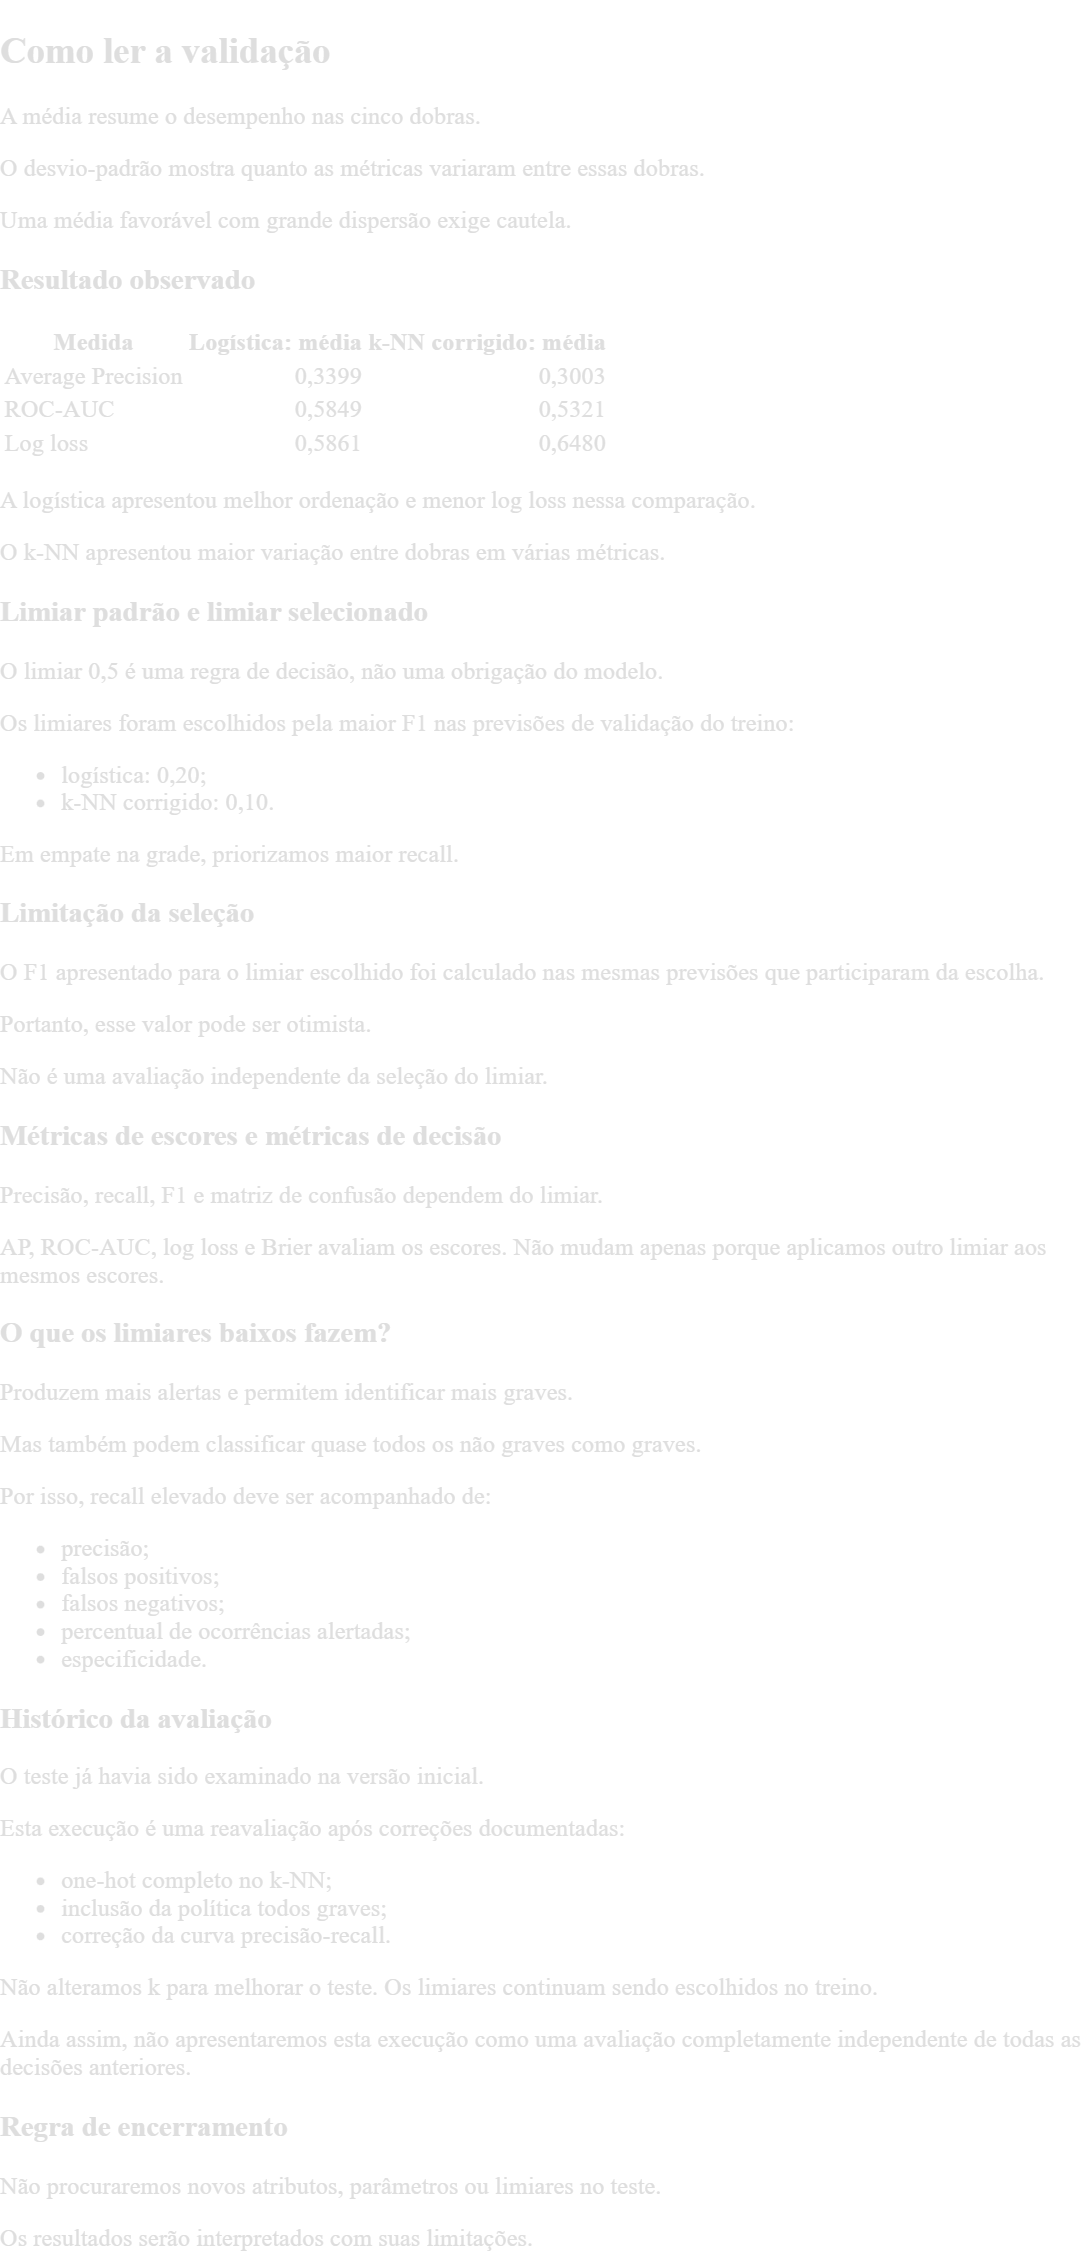

In [ ]:
# Ajusta a logística no treino completo.
pipeline_logistica.fit(X_treino, y_treino)

# Ajusta o k-NN corrigido no treino completo.
pipeline_knn.fit(X_treino, y_treino)

# Cria a referência que aprende a prevalência do treino.
baseline = DummyClassifier(
    strategy="prior",
    random_state=42
)

# Ajusta o baseline.
baseline.fit(X_treino, y_treino)

# Produz os escores no teste sem novo ajuste.
p_teste_logistica = pipeline_logistica.predict_proba(X_teste)[:, 1]
p_teste_knn = pipeline_knn.predict_proba(X_teste)[:, 1]
p_teste_baseline = baseline.predict_proba(X_teste)[:, 1]

# Declara as configurações antes de comparar seus resultados.
configuracoes_teste = [
    ("Baseline majoritario", p_teste_baseline, 0.5),
    ("Logistica padrao", p_teste_logistica, 0.5),
    (
        "Logistica limiar CV",
        p_teste_logistica,
        limiares_escolhidos["Logistica"]
    ),
    ("kNN padrao corrigido", p_teste_knn, 0.5),
    (
        "kNN limiar CV corrigido",
        p_teste_knn,
        limiares_escolhidos["kNN"]
    )
]

# Reserva as métricas.
resultados_teste = []

# Reserva as decisões para as matrizes de confusão.
decisoes_teste = {}

# Avalia as configurações declaradas.
for nome, probabilidades, limiar in configuracoes_teste:

    # Calcula as métricas de classificação e dos escores.
    resultado = avaliar_classificacao(
        y_teste,
        probabilidades,
        limiar
    )

    # Registra a configuração.
    resultado["modelo"] = nome
    resultado["limiar"] = limiar

    # Guarda as métricas.
    resultados_teste.append(resultado)

    # Guarda as decisões.
    decisoes_teste[nome] = (
        probabilidades >= limiar
    ).astype(int)


# Cria a política extrema que classifica todas as ocorrências como graves.
pred_todos_graves = np.ones(len(y_teste), dtype=int)

# Guarda essa política para a matriz de confusão.
decisoes_teste["Todos graves"] = pred_todos_graves

# Acrescenta as métricas de decisão dessa política.
resultados_teste.append({
    "modelo": "Todos graves",
    "limiar": np.nan,
    "acuracia": accuracy_score(y_teste, pred_todos_graves),
    "precisao": precision_score(
        y_teste,
        pred_todos_graves,
        zero_division=0
    ),
    "recall": recall_score(
        y_teste,
        pred_todos_graves,
        zero_division=0
    ),
    "F1": f1_score(
        y_teste,
        pred_todos_graves,
        zero_division=0
    ),
    # A política foi definida como decisão, não como probabilidade estimada.
    "AP": np.nan,
    "ROC_AUC": np.nan,
    "log_loss": np.nan,
    "Brier": np.nan
})

# Organiza a tabela final.
tabela_final_teste = pd.DataFrame(
    resultados_teste
).set_index("modelo")

# Exibe as métricas.
display(tabela_final_teste.round(4))

# Reserva indicadores que tornam o volume de alertas explícito.
indicadores_alertas = []

# Percorre as decisões já calculadas.
for nome, previsoes in decisoes_teste.items():

    # Calcula a matriz na ordem fixa das classes.
    matriz = confusion_matrix(
        y_teste,
        previsoes,
        labels=[0, 1]
    )

    # Separa os quatro resultados.
    vn, fp, fn, vp = matriz.ravel()

    # Registra o volume de alertas e a capacidade de reconhecer não graves.
    indicadores_alertas.append({
        "modelo": nome,
        "alertas": int(vp + fp),
        "alertas_pct": (vp + fp) / len(y_teste) * 100,
        "falsos_positivos": int(fp),
        "falsos_negativos": int(fn),
        "especificidade": vn / (vn + fp)
    })

    # Identifica a matriz.
    print("\n", nome)

    # Exibe as contagens.
    display(pd.DataFrame(
        matriz,
        index=["Real nao grave", "Real grave"],
        columns=["Previsto nao grave", "Previsto grave"]
    ))

# Exibe os indicadores de utilização dos alertas.
display(
    pd.DataFrame(indicadores_alertas)
    .set_index("modelo")
    .round(4)
)

,acuracia,precisao,recall,F1,AP,ROC_AUC,log_loss,Brier,limiar
modelo,,,,,,,,,
Baseline majoritario,0.7175,0.0000,0.0000,0.0000,0.2825,0.5000,0.5953,0.2027,0.5
Logistica padrao,0.7175,0.0000,0.0000,0.0000,0.3367,0.5834,0.5867,0.1992,0.5
Logistica limiar CV,0.3119,0.2876,0.9720,0.4439,0.3367,0.5834,0.5867,0.1992,0.2
kNN padrao corrigido,0.6765,0.3027,0.1113,0.1627,0.2835,0.4991,0.7932,0.2271,0.5
kNN limiar CV corrigido,0.3252,0.2885,0.9468,0.4422,0.2835,0.4991,0.7932,0.2271,0.1
Todos graves,0.2825,0.2825,1.0000,0.4406,NaN,NaN,NaN,NaN,NaN



 Baseline majoritario


,Previsto nao grave,Previsto grave
Real nao grave,15611,0
Real grave,6148,0



 Logistica padrao


,Previsto nao grave,Previsto grave
Real nao grave,15611,0
Real grave,6148,0



 Logistica limiar CV


... (4 outputs left out)

,Previsto nao grave,Previsto grave
Real nao grave,1255,14356
Real grave,327,5821



 Todos graves


,Previsto nao grave,Previsto grave
Real nao grave,0,15611
Real grave,0,6148


,alertas,alertas_pct,falsos_positivos,falsos_negativos,especificidade
modelo,,,,,
Baseline majoritario,0,0.0000,0,6148,1.0000
Logistica padrao,0,0.0000,0,6148,1.0000
Logistica limiar CV,20776,95.4823,14800,172,0.0520
kNN padrao corrigido,2260,10.3865,1576,5464,0.8990
kNN limiar CV corrigido,20177,92.7294,14356,327,0.0804
Todos graves,21759,100.0000,15611,0,0.0000


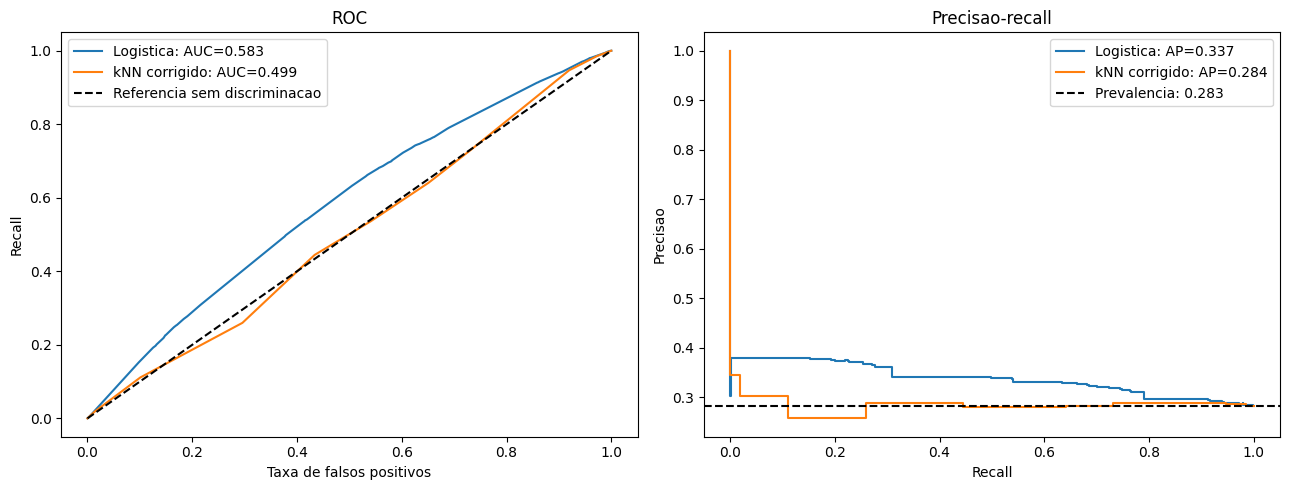

Graves com escore zero no k-NN corrigido: 89
AP do baseline de escore constante: 0.2825497495289306


In [ ]:
# Cria os painéis.
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

# Desenha somente os modelos que produzem escores distintos.
for nome, probabilidades in [
    ("Logistica", p_teste_logistica),
    ("kNN corrigido", p_teste_knn)
]:

    # Calcula os pontos da curva ROC.
    fpr, tpr, _ = roc_curve(
        y_teste,
        probabilidades
    )

    # Desenha a ROC.
    eixos[0].plot(
        fpr,
        tpr,
        label=(
            f"{nome}: AUC="
            f"{roc_auc_score(y_teste, probabilidades):.3f}"
        )
    )

    # Calcula os pontos da curva precisão-recall.
    precisao_curva, recall_curva, _ = precision_recall_curve(
        y_teste,
        probabilidades
    )

    # Desenha em degraus, sem sugerir uma interpolação linear contínua.
    eixos[1].step(
        recall_curva[::-1],
        precisao_curva[::-1],
        where="pre",
        label=(
            f"{nome}: AP="
            f"{average_precision_score(y_teste, probabilidades):.3f}"
        )
    )

# Mostra a referência sem discriminação na ROC.
eixos[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Referencia sem discriminacao"
)

# Mostra a prevalência na precisão-recall.
eixos[1].axhline(
    y_teste.mean(),
    linestyle="--",
    color="black",
    label=f"Prevalencia: {y_teste.mean():.3f}"
)

# Nomeia os eixos.
eixos[0].set_title("ROC")
eixos[0].set_xlabel("Taxa de falsos positivos")
eixos[0].set_ylabel("Recall")

eixos[1].set_title("Precisao-recall")
eixos[1].set_xlabel("Recall")
eixos[1].set_ylabel("Precisao")

# Mostra as legendas.
eixos[0].legend()
eixos[1].legend()

# Ajusta e exibe.
plt.tight_layout()
plt.show()

# Identifica os graves reais.
mascara_graves_teste = y_teste.to_numpy() == 1

# Conta escores zero atribuídos a graves pelo k-NN.
print(
    "Graves com escore zero no k-NN corrigido:",
    int(np.sum(p_teste_knn[mascara_graves_teste] == 0))
)

# Informa a AP do baseline sem desenhar a diagonal enganosa.
print(
    "AP do baseline de escore constante:",
    average_precision_score(y_teste, p_teste_baseline)
)

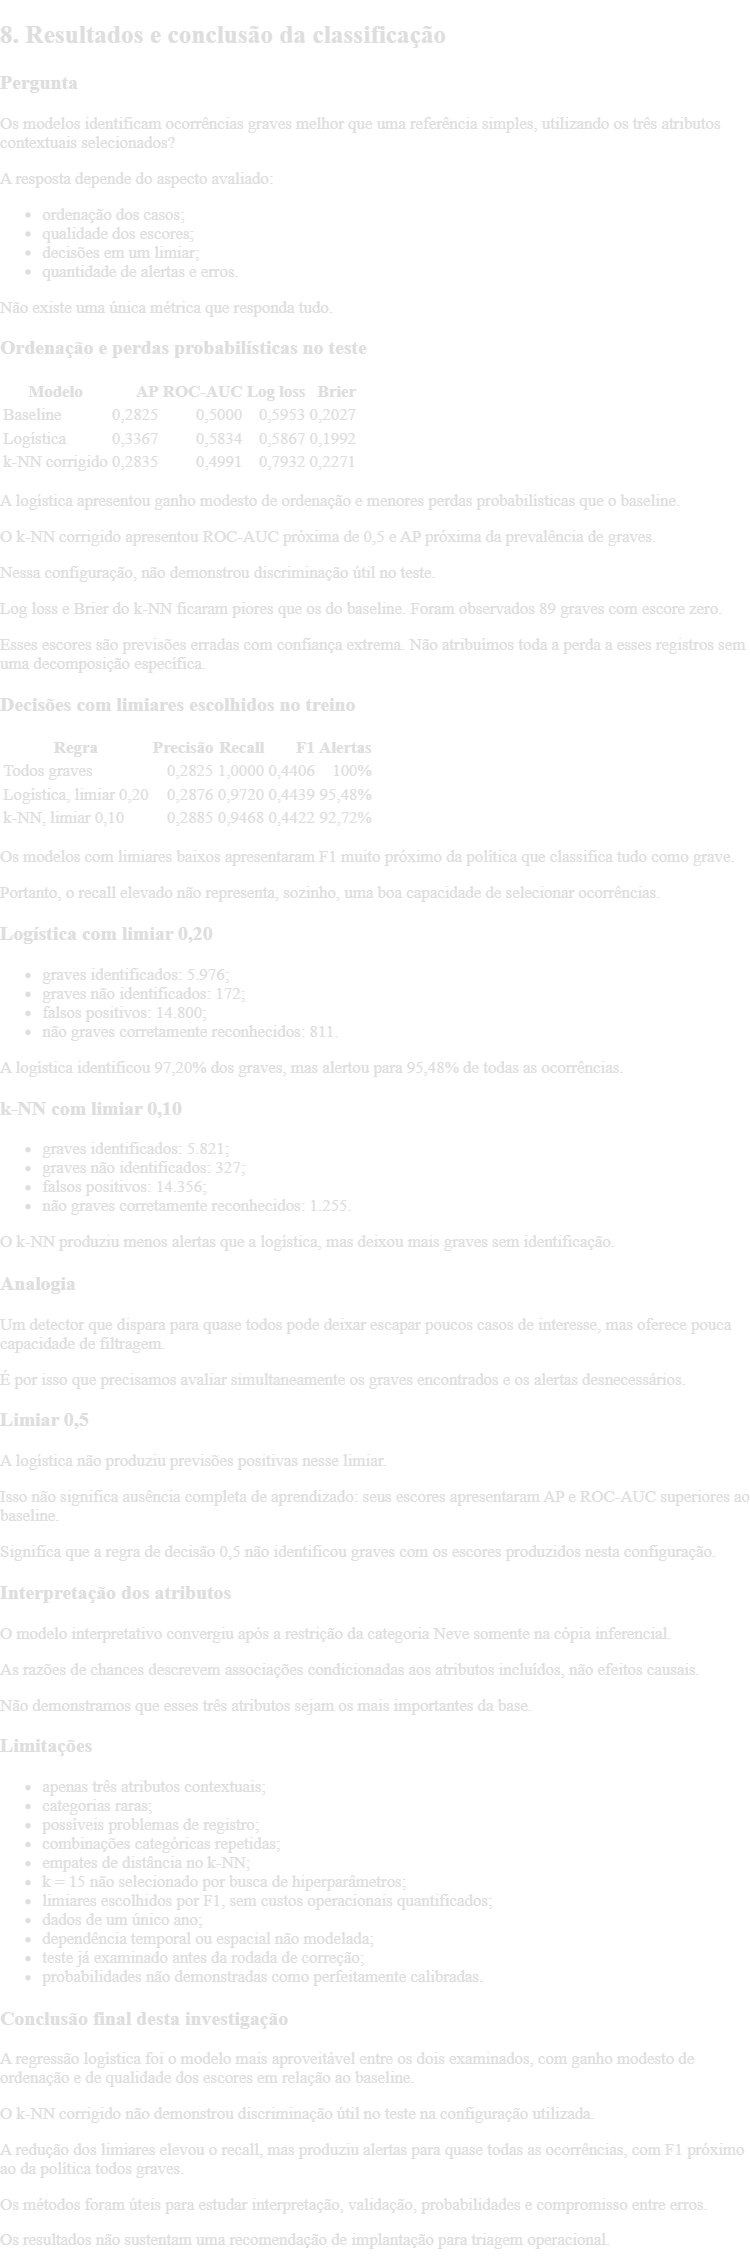

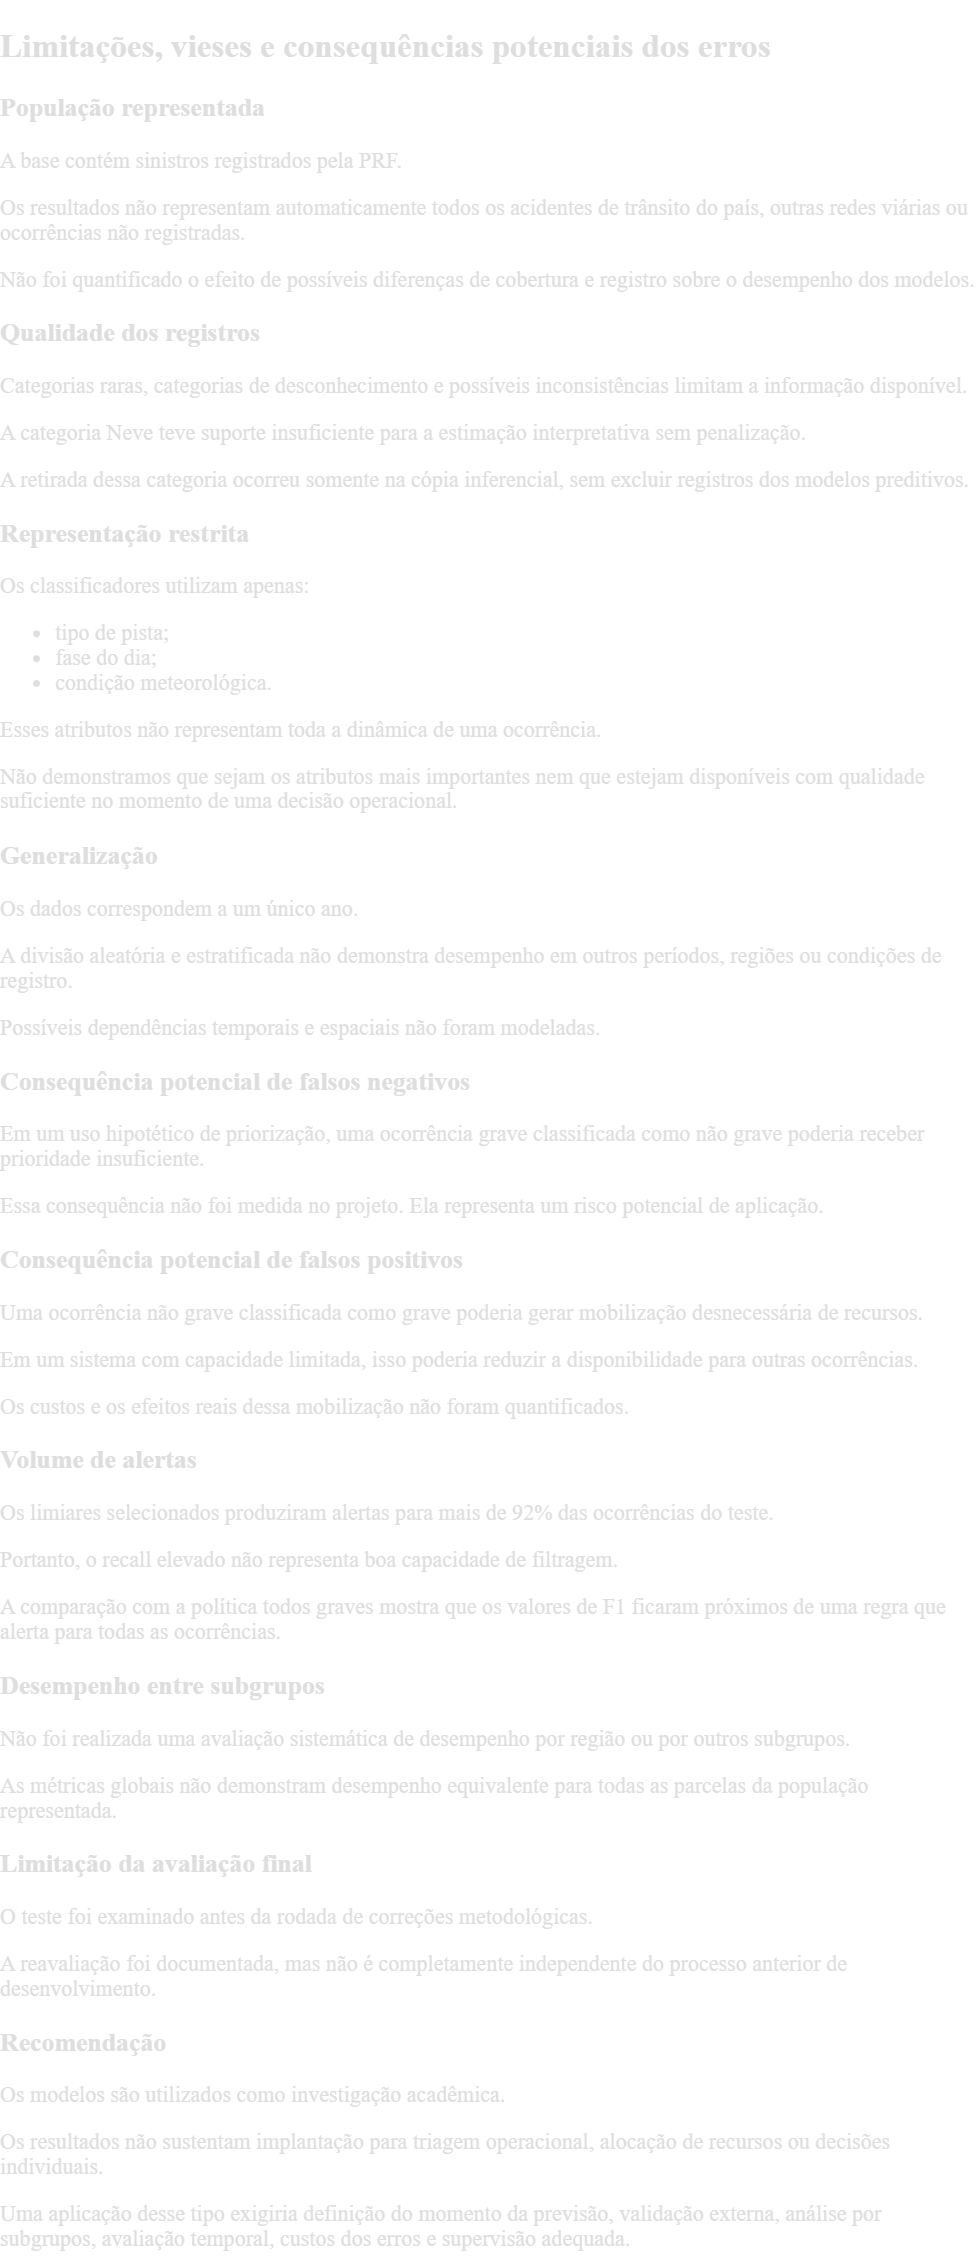

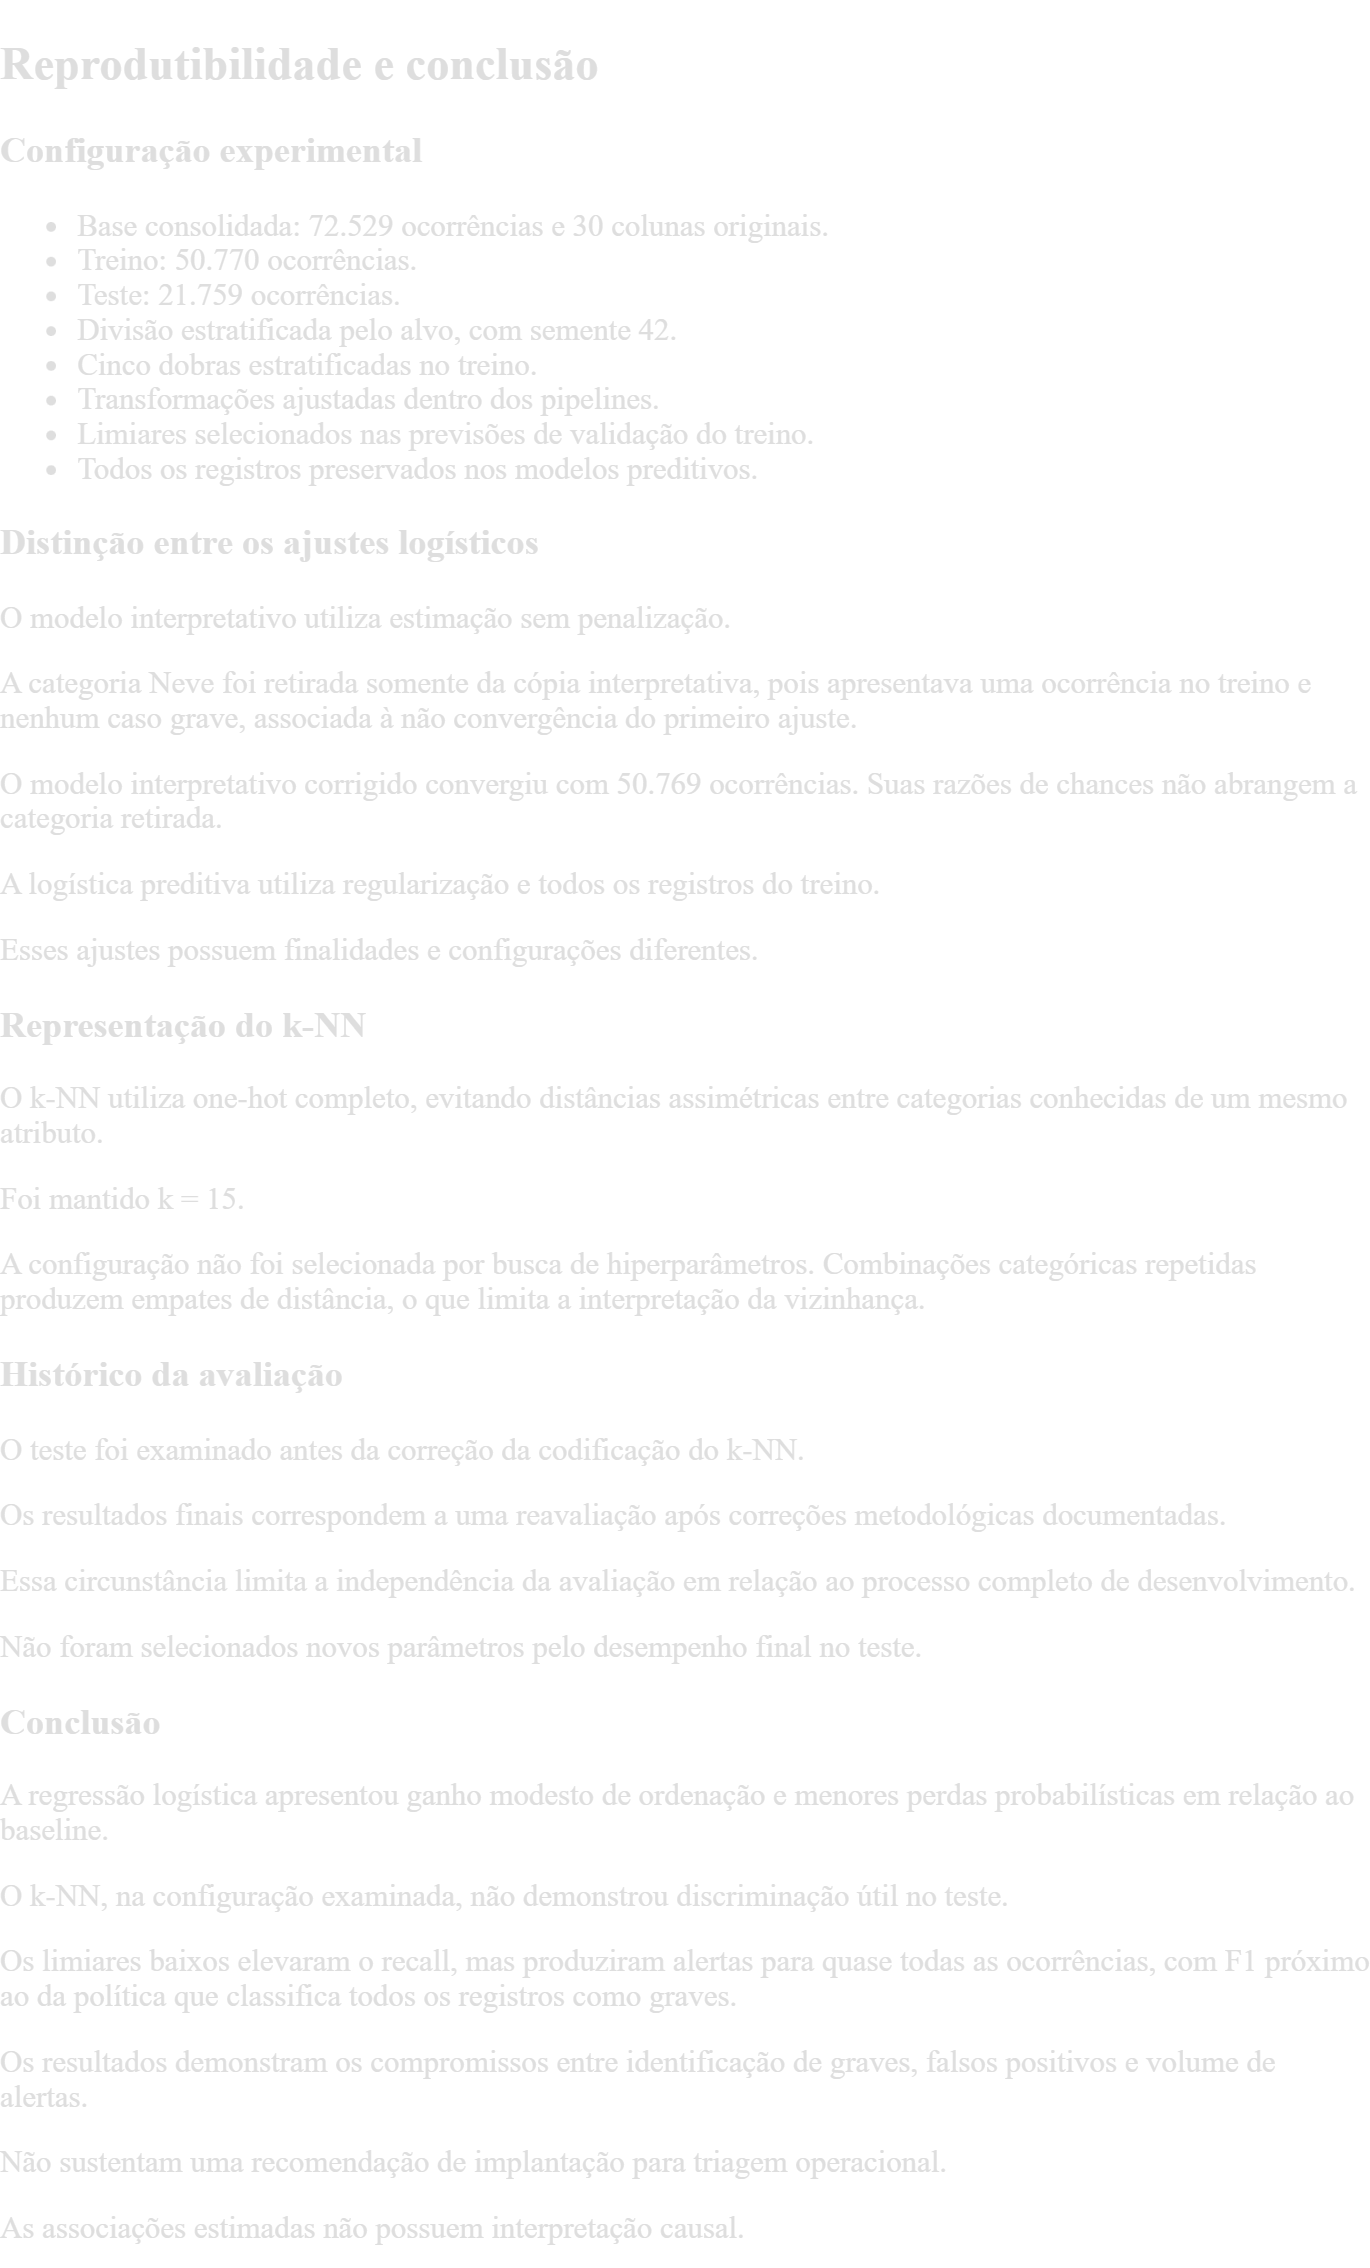